# 12. Counting a shower

**The question.** Notebook 11 gave every reticle a count, estimated from its hit map alone. A
calorimeter does not use these counts one by one: it adds them up, layer by layer and over the
whole shower. This notebook asks:

- how the counts of the reticles add up to a layer profile and to the total of a shower;
- how well the total follows the true number of crossings, shower by shower;
- what the calibration depends on: the density of the reticles and the depth in the shower;
- how many bits a count costs, compared with sending the hit map.

**Where this notebook sits.** Each box below holds what one stage makes, the files that store it
are under the box, and the program that makes it is over the arrow. This notebook starts from the
count of every reticle and ends with the totals of a shower.

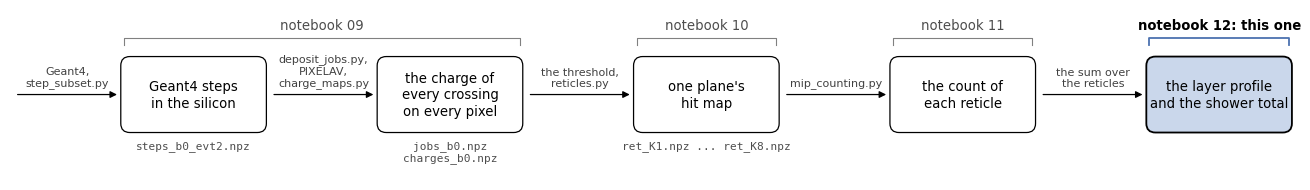

In [1]:
import os, sys
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', 'analysis', 'pixelav')))
import sketches                  # drawn schematics, no data (analysis/pixelav/sketches.py)

sketches.chain('12')
plt.show()

**What you need beforehand**

- Notebook 11. It builds the estimators used here (`hits`, `clusters`, `cluster_shape`, `gbt`,
  `gbt_layer`, and `analog`, which reads the charge and serves as a reference), scores them reticle
  by reticle, and introduces the five blocks of showers. Notebook 10 before it defines the
  crossing, the reticle, the readout and the truth `n_frac`. This notebook uses those words without
  defining them again.
- Four input files, in `models/reticle_study/` or in the directory named by the environment
  variable `CALOMAPS_RETICLE_STUDY`:
  - `ret_K1.npz`: 200 showers of 50 GeV photons, cut into reticles;
  - `ret_K2.npz`, `ret_K4.npz`, `ret_K8.npz`: the same 200 showers, the charge of 2, 4 or 8
    showers added pixel by pixel on the same planes, to raise the density.

  They are written by `analysis/pixelav/reticles.py` from the charge maps of
  `analysis/pixelav/charge_maps.py`, which run PIXELAV on the Geant4 steps. Making them again needs
  PIXELAV and a sensor field map that is not part of this repository, so this notebook is kept
  with its outputs. The commands are in section 9 of `docs/reticle_mip_counting.md`.
- The study behind this notebook is `docs/reticle_mip_counting.md` (the write-up, below). Its
  sections 6.2 (shower totals), 6.4 (density and depth) and 6.7 (data volume) report the results
  that this notebook rebuilds.

**Words used below**

- *stack*: adds the charge of K showers pixel by pixel on the same planes (`reticles.py
  --overlay K`); K = 1 is a single shower. Stacking raises the density; a stack is not a shower of
  K x 50 GeV (its core is wider and its depth profile is that of one 50 GeV shower; write-up
  section 2). mip_counting numbers the stacks with `super_evt`.
- *block* (`fold` in mip_counting): one of five runs of 40 consecutive showers; a stack lies in the
  block of its showers. The *five-block refit* is drawn in section 2.
- *layer weight*: the weight of a reticle in the sum over the shower, set by the tungsten in front
  of its layer (section 1).
- *weighted total*: the sum over the stored reticles of a stack of layer weight x count (or x truth,
  hit pixels, charge). The *unweighted total* takes every weight as 1.
- *spread*: the standard deviation of a total over the stacks divided by its mean, in per cent; the
  standard deviation that divides by n - 1 (ddof = 1, as `mc._spread`).
- *ratio*: estimated total / true total of one stack. We give its mean over the stacks and its
  standard deviation, written "mean +- spread" as in the write-up; the +- is a spread over the
  stacks, not an error.

**What you can change.** In the configuration cell of section 1: `DISPLAY`, the shower drawn layer
by layer in section 3 (any of 0 to 19, the showers of batch 0; the text describes shower 2), and
`ROUND_STEPS`, the steps in which section 4 rounds the `gbt` estimate of each reticle (add 0.5, for
example). With `CHECK_NUMBERS = False`, a check of appendix A that fails prints what differs instead
of stopping the notebook.

## 1. Loading, readout, truth, blocks and layer weights

The first cells repeat section 1 of notebook 11 for the single showers. `mc.prepare` reads the hit
map of every reticle out of its charge image (Gaussian noise added to every pixel, then the
threshold), computes the truth `n_frac`, the clusters and the 49 numbers that the trees read, and
puts every shower into one of the five blocks. The checks are those of notebook 11: the hit pixels
of every reticle, the readout redrawn from its seed and `n_frac` summed over all reticles. The
stacks follow in section 5.

Only reticles holding charge are stored. A reticle without charge has an empty hit map unless the
noise alone lights a pixel (the chance is printed below), and every binary estimator gives an
empty hit map the estimate 0. So the total of a stack, true or estimated, is the sum over its
stored reticles.

In [2]:
import os, sys, time
import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import sklearn

T_START = time.time()
REPO = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA = os.environ.get('CALOMAPS_RETICLE_STUDY', os.path.join(REPO, 'models', 'reticle_study'))
sys.path.insert(0, os.path.join(REPO, 'analysis'))
sys.path.insert(0, os.path.join(REPO, 'analysis', 'pixelav'))
import sensor_crossings as sc    # positions of the sensor layers (analysis/sensor_crossings.py)
import mip_counting as mc        # the counting study (analysis/pixelav/mip_counting.py)
import sketches                  # drawn schematics, no data (analysis/pixelav/sketches.py)


def need(name):
    # the path of an input file, or a clear error naming it
    path = os.path.join(DATA, name)
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"{path} is missing. The ret_K*.npz files are made by analysis/pixelav/reticles.py; see "
            "docs/reticle_mip_counting.md section 9 for the commands. Put them in models/reticle_study/ "
            "or point CALOMAPS_RETICLE_STUDY at their directory.")
    return path


THRESHOLD = mc.THRESHOLD   # electrons: a pixel above this is hit (on)
NOISE = mc.NOISE           # electrons: Gaussian noise per pixel (sigma)
SEED = mc.SEED             # the noise of the readout is drawn from this seed
N_BLOCKS = mc.N_FOLDS      # the write-up cuts the showers into this many blocks
NAMES = ('hits', 'clusters', 'cluster_shape', 'gbt', 'gbt_layer', 'analog')
TABLES = ('hits', 'clusters', 'cluster_shape', 'analog')   # tables: compared with the write-up to its printed digits
TREES = ('gbt', 'gbt_layer')                               # trees: printed beside the write-up, never asserted
COLOUR = {nm: mc.COLOURS[nm] for nm in NAMES}
STYLE = {nm: '-' for nm in NAMES}
STYLE.update(gbt_layer='--', analog=':')
LABEL = {'hits': 'hit count (hits)', 'clusters': 'cluster count (clusters)',
         'cluster_shape': 'shape dictionary (cluster_shape)', 'gbt': 'trees (gbt)',
         'gbt_layer': 'trees with the layer (gbt_layer)', 'analog': 'charge sum (analog)'}
T_FIT = {}                 # seconds per five-block refit
DISPLAY = 2                # the shower drawn layer by layer in section 3 (any of 0 to 19, batch 0)
ROUND_STEPS = (0.25, 1.0)  # section 4: the steps of an 8-bit count (0.25 and 1 are compared with the write-up)
CHECK_NUMBERS = True       # False: a check of appendix A that fails prints what differs instead of stopping


def check(condition, message):
    # a check of a result against the study code or the write-up: silent when it holds; when it fails, it
    # stops the notebook (CHECK_NUMBERS True) or prints "check skipped: " and the message (CHECK_NUMBERS False)
    if not condition:
        if CHECK_NUMBERS:
            raise AssertionError(message)
        print("check skipped: " + message)


print(f"repository: {REPO}\ndata: {DATA}")
print(f"threshold {THRESHOLD:g} e, noise {NOISE:g} e, seed {SEED}, {N_BLOCKS} blocks; estimators: {', '.join(NAMES)}")
print(f"numpy {np.__version__}, scikit-learn {sklearn.__version__}")

repository: /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms
data: /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms/models/reticle_study
threshold 1000 e, noise 100 e, seed 1, 5 blocks; estimators: hits, clusters, cluster_shape, gbt, gbt_layer, analog
numpy 2.2.6, scikit-learn 1.7.0


In [3]:
R1 = mc.load_reticles(need('ret_K1.npz'))        # load_reticles applies mc.with_truth_objects
with np.load(need('ret_K1.npz')) as d:           # arrays that load_reticles leaves out
    GUN = f"{float(d['sim_gun_energy_GeV']):g} GeV {d['sim_gun_particle']}"
    SIM_SEEDS = [str(s) for s in d['input_sim_seed']]
    GEO_CENTRES = d['geo_si_centers_mm']         # mm: the depth of each sensor layer in the simulation
t0 = time.time()
(D1,), EV_BLOCK = mc.prepare([R1], ['K1'], THRESHOLD, NOISE, SEED, N_BLOCKS)
NY, NX = D1['ny'], D1['nx']
N_LAYERS = int(D1['layer'].max()) + 1
N_SHOWERS = int(R1['n_events'])
print(f"{N_SHOWERS} showers of {GUN}; mc.prepare took {time.time() - t0:.0f} s; reticles of {NX} x {NY} pixels, "
      f"{N_LAYERS} layers")
print(f"K1: {D1['n']:,} reticles holding charge from {D1['n_super_events']} single showers; "
      f"{len(D1['pix']['idx']):,} hit pixels in {len(D1['cl']['size']):,} clusters; {D1['feat'].shape[1]} numbers "
      "per reticle for the trees")
print("per reticle, used below: super_evt (the shower, later the stack), fold (its block), layer, module, "
      "n_hits, q_sum (charge before noise), n_frac (the truth)")

200 showers of 50 GeV gamma; mc.prepare took 4 s; reticles of 21 x 13 pixels, 30 layers
K1: 600,628 reticles holding charge from 200 single showers; 3,258,453 hit pixels in 880,356 clusters; 49 numbers per reticle for the trees
per reticle, used below: super_evt (the shower, later the stack), fold (its block), layer, module, n_hits, q_sum (charge before noise), n_frac (the truth)


In [4]:
assert np.array_equal(D1['n_hits'], np.bincount(D1['pix']['ret'], minlength=D1['n'])), \
    "n_hits is not the number of hit pixels"
print("check: n_hits is the number of hit pixels of every K1 reticle")

img = R1['img']
S_PIX = NY * NX
rng = np.random.default_rng((SEED, 0))          # mc.prepare draws the noise of file i from (SEED, i); K1 is file 0
idx = []
for a in range(0, len(img), mc.CHUNK):
    b = img[a:a + mc.CHUNK]
    on = b + rng.standard_normal(b.shape, dtype=np.float32) * np.float32(NOISE) > THRESHOLD
    idx.append(np.flatnonzero(on) + a * S_PIX)
assert np.array_equal(np.concatenate(idx), D1['pix']['idx']), \
    "the hit map is not the charge plus the readout's noise above the threshold"
del idx, on, b
print("check: the readout's noise, redrawn from its seed, gives the same hit pixels in every K1 reticle")
print(f"the chance that the noise alone lights one of the {S_PIX} pixels of a reticle without charge: "
      f"{S_PIX * norm.sf(THRESHOLD / NOISE):.1e}")

info = D1['truth_info']
gap = abs(D1['n_frac'].sum() - info['above_cut'])
assert gap <= 1e-3 + info['above_cut_incomplete'], f"n_frac sums to {D1['n_frac'].sum():.3f}, not to the crossings"
print(f"check: n_frac sums to the {info['above_cut']:,} crossings above {THRESHOLD:g} e of the {N_SHOWERS} showers "
      f"(difference {gap:.1e})")

check: n_hits is the number of hit pixels of every K1 reticle


check: the readout's noise, redrawn from its seed, gives the same hit pixels in every K1 reticle
the chance that the noise alone lights one of the 273 pixels of a reticle without charge: 2.1e-21
check: n_frac sums to the 805,355 crossings above 1000 e of the 200 showers (difference 6.0e-06)


In [5]:
BLOCK = N_SHOWERS // N_BLOCKS                     # showers per block
assert np.array_equal(EV_BLOCK, np.arange(N_SHOWERS) // BLOCK), "the blocks are not runs of consecutive showers"
assert np.array_equal(D1['fold'][R1['part_reticle']], R1['part_evt'] // BLOCK), \
    "a reticle lies in another block than the shower of its particle rows"
print(f"check: block f holds showers {BLOCK} f to {BLOCK} f + {BLOCK - 1}, and every particle row of the file sits in "
      "a reticle of its own shower's block (as mc.prepare requires)")
print("reticles per block: " + ', '.join(f"{n:,}" for n in np.bincount(D1['fold'], minlength=N_BLOCKS)))

check: block f holds showers 40 f to 40 f + 39, and every particle row of the file sits in a reticle of its own shower's block (as mc.prepare requires)
reticles per block: 119,576, 120,570, 120,492, 120,733, 119,257


**The layer weights.** Each layer samples the shower behind its own tungsten plate, and the plates
come in two thicknesses (read from the geometry file below and drawn to scale), so the calorimeter
sum gives each reticle the weight of its plate in units of the thin one: `layer_w`, the write-up's
`--layer-weights 20:2` (`mc.parse_layer_weights` and `mc.layer_weights`). The write-up gives every
shower total with and without these weights, and so do we.

tungsten in geometry/my_custom_ecal.xml: 20 layers behind 2.5 mm, then 10 layers behind 5 mm; ratio of the plates 2


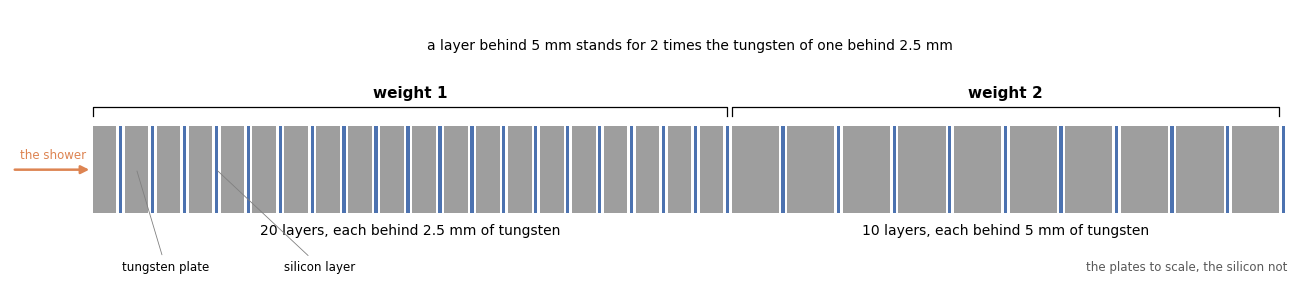

In [6]:
plates = []                                       # (layers, tungsten in front of each in mm), from the geometry
for lay in ET.parse(os.path.join(REPO, 'geometry', 'my_custom_ecal.xml')).getroot().iter('layer'):
    w_ = next(s.get('thickness') for s in lay.iter('slice') if s.get('material', '').startswith('Tungsten'))
    value, unit = w_.split('*')
    plates.append((int(lay.get('repeat')), float(value) * {'mm': 1.0, 'cm': 10.0}[unit]))
print("tungsten in geometry/my_custom_ecal.xml: " + ', then '.join(f"{n} layers behind {t:g} mm" for n, t in plates)
      + f"; ratio of the plates {plates[1][1] / plates[0][1]:g}")

sketches.layer_weights(plates[0][0], plates[0][1], plates[1][0], plates[1][1])
plt.show()

In [7]:
centres = sc.si_layer_centers()                   # mm: the depth of each sensor layer
spacing = np.diff(centres)
L_WIDE = int(np.flatnonzero(spacing > spacing[0] + 1e-6)[0]) + 1     # the first layer after a wider gap
print(f"layer spacing: {spacing[0]:.2f} mm up to layer {L_WIDE - 1}, then {spacing[L_WIDE - 1]:.2f} mm "
      f"(the same to the last layer: {bool(np.allclose(spacing[L_WIDE - 1:], spacing[L_WIDE - 1]))})")
assert np.allclose(np.diff(GEO_CENTRES), spacing) and L_WIDE == plates[0][0], \
    "the layer depths of the reticle file, sensor_crossings and the geometry file disagree"
print(f"check: the reticle file's own layer depths have the same spacing, and the spacing widens after the first "
      f"{plates[0][0]} layers")

LAYER_WEIGHTS = '20:2'      # the write-up's --layer-weights: weight 2 from layer 20 on, 1 before
D1['layer_w'] = mc.layer_weights(mc.parse_layer_weights(LAYER_WEIGHTS), D1['layer'])
W_FROM, W_VALUE = int(LAYER_WEIGHTS.split(':')[0]), float(LAYER_WEIGHTS.split(':')[1])
by_hand = np.where(D1['layer'] >= W_FROM, W_VALUE, 1.0)
assert W_VALUE == plates[1][1] / plates[0][1], \
    f"the weight {W_VALUE:g} is not the ratio of the plates, {plates[1][1] / plates[0][1]:g}"
assert np.array_equal(D1['layer_w'], by_hand) and W_FROM == L_WIDE, \
    "layer_w differs from the weights read off the layers by hand, or does not change where the spacing does"
print(f"check: layer_w is 1 for layers 0 to {W_FROM - 1} and {W_VALUE:g}, the ratio of the plates, for layers {W_FROM} "
      f"to {N_LAYERS - 1} in all {D1['n']:,} reticles (read off their layers by hand), changing where the spacing widens")
print(f"layers {W_FROM} to {N_LAYERS - 1} hold {D1['n_frac'][D1['layer'] >= W_FROM].sum() / D1['n_frac'].sum():.1%} "
      "of the crossings of the single showers")

layer spacing: 3.75 mm up to layer 19, then 6.25 mm (the same to the last layer: True)
check: the reticle file's own layer depths have the same spacing, and the spacing widens after the first 20 layers
check: layer_w is 1 for layers 0 to 19 and 2, the ratio of the plates, for layers 20 to 29 in all 600,628 reticles (read off their layers by hand), changing where the spacing widens
layers 20 to 29 hold 12.0% of the crossings of the single showers


## 2. Every shower estimated by models that never saw it

Notebook 11 fitted its tables and models on showers 0 to 159 and scored them on 40 test showers:
one turn of the five drawn below. A shower total needs an estimate for every reticle of every
shower, so here we do all five turns, for every estimator: each block of 40 showers is estimated by
tables and models fitted on the other four blocks. `mc.crossfit` does this and runs
`mc.check_unseen` on every block, so each shower is estimated by models that never saw it. As in
the write-up's single-shower run, everything is trained on single showers.

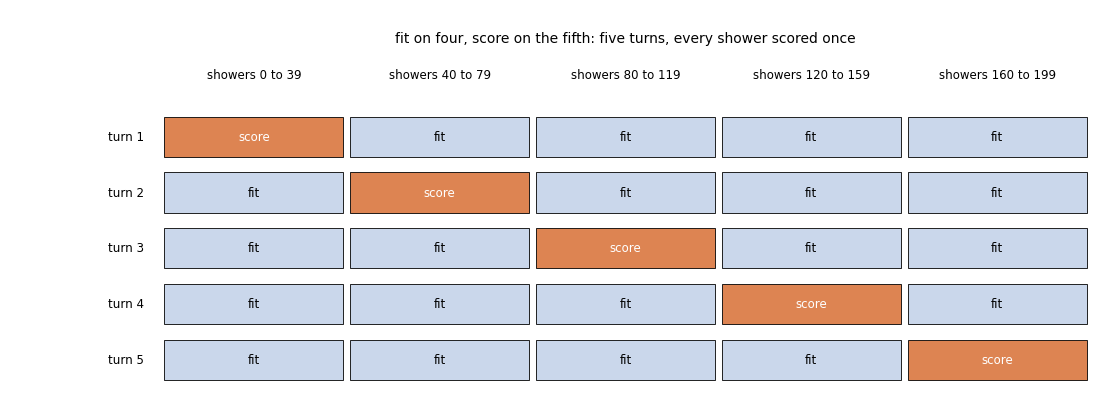

In [8]:
sketches.five_blocks(N_SHOWERS, N_BLOCKS)
plt.show()

In [9]:
t0 = time.time()
P1 = mc.crossfit([D1], 'n_frac', NAMES, N_BLOCKS, ['K1'], ['K1'], n_events=N_SHOWERS)['K1']
T_FIT['section 2: trained on K1, applied to K1'] = time.time() - t0
print(f"five-block refit of the {len(NAMES)} estimators on the single showers: {time.time() - t0:.0f} s")
bad = [nm for nm in NAMES if not np.all(np.isfinite(P1[nm]))]
assert not bad, f"reticles without a finite estimate: {bad}"
print(f"check: every one of the {D1['n']:,} reticles has a finite estimate from every estimator, no NaN (as mc.crossfit "
      "requires)")
print("appendix A checks these estimates against the write-up's table 6.1 and sets the rms of each block "
      "beside it")

five-block refit of the 6 estimators on the single showers: 151 s
check: every one of the 600,628 reticles has a finite estimate from every estimator, no NaN (as mc.crossfit requires)
appendix A checks these estimates against the write-up's table 6.1 and sets the rms of each block beside it


## 3. From reticles to layers

The estimate of a layer is the sum of the estimates of all its reticles, on every module; its truth
is the sum of their `n_frac`, the crossings of that layer. First one shower, `DISPLAY`: shower 2 of
the first batch of 20, the display shower of notebooks 09 and 10. We check from the particle rows
of the file that it is that shower.

check: the 3,113 reticles of shower 2 hold the particle rows of event 2 (part_evt) and of no other; the file's first input holds its events 0 to 19 and is batch b0 (simulation seed 424242): this is shower 2 of batch 0, the shower of notebooks 09 and 10


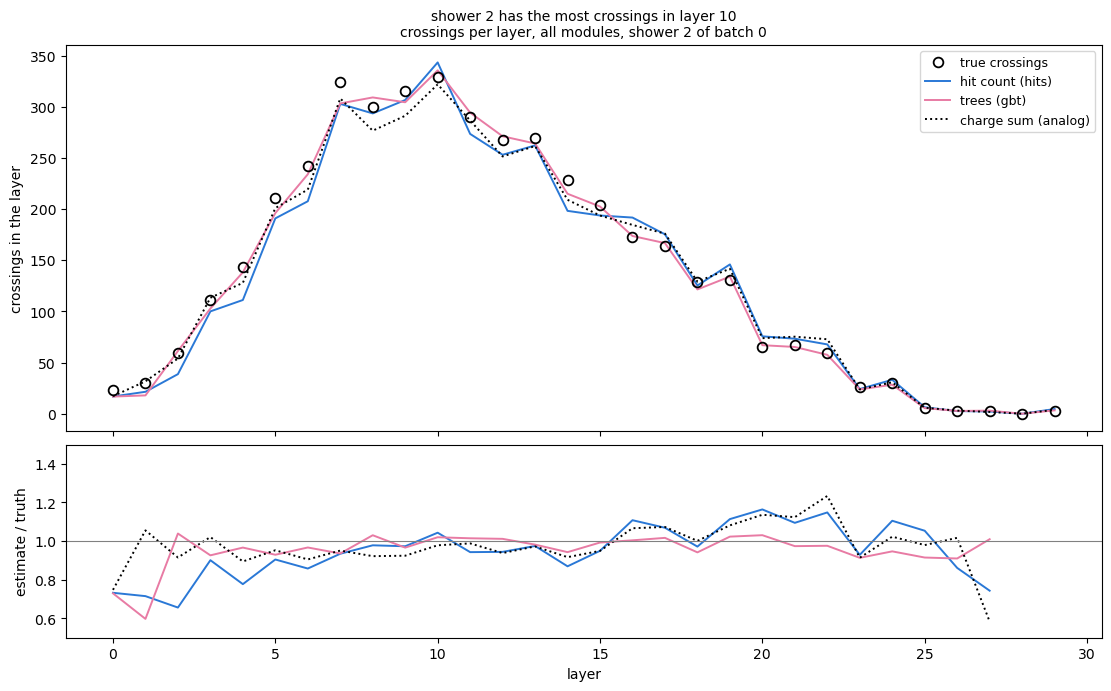

shower 2: 4,205 true crossings, the most in layer 10; over the 200 showers the layer with the most crossings has the median 12 (from 8 to 20)
summed over the layers: hits 4,042, clusters 4,080, cluster_shape 4,084, gbt 4,119, gbt_layer 4,137, analog 4,087
layers 0 to 4: truth 366, hits 288, clusters 284, cluster_shape 269, gbt 337, gbt_layer 352, analog 344
layers 20 to 29: truth 262, hits 290, clusters 248, cluster_shape 288, gbt 257, gbt_layer 256, analog 291


In [10]:
in_disp = D1['super_evt'] == DISPLAY
row_in = in_disp[R1['part_reticle']]
assert np.all(R1['part_evt'][row_in] == DISPLAY) and np.all(row_in[R1['part_evt'] == DISPLAY]), \
    "the reticles of shower 2 hold particle rows of other showers, or miss some of shower 2"
batch = os.path.basename(os.path.dirname(str(R1['inputs'][0])))
assert R1['input_event_offset'][0] == 0 and DISPLAY < R1['input_n_events'][0] and batch == 'b0', \
    "shower 2 of the file is not shower 2 of batch 0"
print(f"check: the {int(in_disp.sum()):,} reticles of shower {DISPLAY} hold the particle rows of event {DISPLAY} (part_evt) "
      f"and of no other; the file's first input holds its events 0 to {R1['input_n_events'][0] - 1} and is batch "
      f"{batch} (simulation seed {SIM_SEEDS[0]}): this is shower {DISPLAY} of batch 0"
      + (", the shower of notebooks 09 and 10" if DISPLAY == 2 else ""))

L = np.arange(N_LAYERS)
W_LAYER = mc.layer_weights(mc.parse_layer_weights(LAYER_WEIGHTS), L)
TRUE_D = np.bincount(D1['layer'][in_disp], D1['n_frac'][in_disp], N_LAYERS)
EST_D = {nm: np.bincount(D1['layer'][in_disp], P1[nm][in_disp], N_LAYERS) for nm in NAMES}
peak_d = int(np.argmax(TRUE_D))
fig, axs = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True, gridspec_kw={'height_ratios': [2, 1]},
                        constrained_layout=True)
axs[0].plot(L, TRUE_D, 'o', color='k', mfc='none', ms=7, mew=1.3, zorder=3, label='true crossings')
SHOWN_1 = ('hits', 'gbt', 'analog')                # the truth, the hit count, the trees and the charge sum
for nm in SHOWN_1:
    axs[0].plot(L, EST_D[nm], STYLE[nm], color=COLOUR[nm], lw=1.4, label=LABEL[nm])
axs[0].set_ylabel('crossings in the layer')
axs[0].set_title(f'shower {DISPLAY} has the most crossings in layer {peak_d}\n'
                 f'crossings per layer, all modules, shower {DISPLAY} of batch 0', fontsize=10)
axs[0].legend(fontsize=9, loc='upper right')
with np.errstate(invalid='ignore', divide='ignore'):
    for nm in SHOWN_1:
        axs[1].plot(L, EST_D[nm] / TRUE_D, STYLE[nm], color=COLOUR[nm], lw=1.4)
axs[1].axhline(1, color='0.5', lw=0.8)
axs[1].set_ylim(0.5, 1.5)
axs[1].set_ylabel('estimate / truth')
axs[1].set_xlabel('layer')
plt.show()
peaks = np.argmax(np.bincount(D1['super_evt'] * N_LAYERS + D1['layer'], D1['n_frac'],
                              N_SHOWERS * N_LAYERS).reshape(N_SHOWERS, N_LAYERS), axis=1)
print(f"shower {DISPLAY}: {TRUE_D.sum():,.0f} true crossings, the most in layer {peak_d}; over the {N_SHOWERS} showers the "
      f"layer with the most crossings has the median {np.median(peaks):.0f} (from {peaks.min()} to {peaks.max()})")
print("summed over the layers: " + ', '.join(f"{nm} {EST_D[nm].sum():,.0f}" for nm in NAMES))
for a_, b_ in ((0, 4), (20, 29)):
    print(f"layers {a_} to {b_}: truth {TRUE_D[a_:b_ + 1].sum():,.0f}, " +
          ', '.join(f"{nm} {EST_D[nm][a_:b_ + 1].sum():,.0f}" for nm in NAMES))

- Shower 2 has the most crossings in layer 10. Over the 200 showers the layer with the most
  crossings is 12 at the median (8 to 20): this shower peaks early.
- Its 4,205 true crossings are estimated as 4,042 (`hits`) to 4,137 (`gbt_layer`).
- In layers 0 to 4 it has 366 true crossings. The tables on the hit map give 269 to 288, `analog`
  344, `gbt` 337 and `gbt_layer` 352.
- In layers 20 to 29 it has 262. `hits` and `cluster_shape` give 290 and 288, `gbt` 257.

Over all 200 showers, the ratio per layer is the sum of the estimates over the sum of the truth.
The figure gives it for every estimator; the lower panel shows where the crossings are.

The write-up's numbers printed beside our own are typed into the next cell when this notebook is
built, not read from a file; appendix A checks its other comparisons.

In [11]:
# docs/reticle_mip_counting.md, read when this notebook was built
WRITEUP = {
    # 6.2: spread weighted and unweighted [%], ratio of the weighted totals: mean and spread over the showers
    'section_6_2': {'true crossings': (2.2, 7.0), 'hit pixels': (3.8, 8.2), 'charge': (3.4, 7.8),
                    'hits': (3.9, 8.5, 1.012, 0.027), 'clusters': (2.8, 7.3, 1.0, 0.017),
                    'cluster_shape': (3.0, 7.7, 1.011, 0.016), 'analog': (3.3, 7.7, 1.012, 0.022),
                    'gbt': (2.6, 7.3, 0.999, 0.011), 'gbt_layer': (2.9,),
                    'unweighted_ratio': 0.998, 'missing': 0.2,
                    'bootstrap': [('gbt', 'true crossings', 0.44, 0.07), ('hit pixels', 'gbt', 1.21, 0.15),
                                  ('charge', 'gbt', 0.81, 0.14), ('clusters', 'gbt', 0.22, 0.10),
                                  ('gbt_layer', 'gbt', 0.32, 0.06)],
                    'rounding': {'none': 2.60, 0.25: 2.62, 1.0: 2.67, 'shift_1': 5}},
    'spread_truth_per_K': [2.2, 1.5, 1.1, 0.8],                   # caption of the 6.4 figure [%]
    # 6.4: estimate / truth in groups of layers, single showers
    'section_6_4_depth': {'groups': [(0, 4), (5, 9), (10, 14), (15, 19), (20, 29)],
                          'ratio': {'hits': [0.72, 0.94, 1.0, 1.01, 1.12], 'clusters': [0.72, 0.92, 1.03, 1.04, 1.01],
                                    'gbt': [0.89, 0.99, 1.01, 1.0, 1.0], 'gbt_layer': [0.99, 1.0, 1.0, 1.0, 1.0]},
                          'share': [3.1, 21.4, 35.5, 27.9, 12.0], 'hits_per_crossing': [2.9, 3.5, 4.0, 4.4, 4.7]},
    # 6.7: bits per reticle with a hit and kbit per shower, 21 x 13 reticles, single showers
    'section_6_7': {'bits': (273, 51, 8), 'kbit': (781, 147, 22.9),
                    'count_smaller': (6, 34),                     # than the addresses, than the bitmap
                    'with_address': (10, 3.4, 16),                # bits of reticle address; the same two ratios
                    'zs_over_count_K8': 10,
                    'clip_loss': {'K1': 0.1, 'K8': 12}, 'above_range_K8': 20, 'densest_K8': 441},
}


def digits_match(x, doc, nd):
    # x rounds to the write-up's number printed with nd decimals (half a unit of its last digit)
    return abs(x - doc) <= 0.5 * 10.0 ** -nd + 1e-9

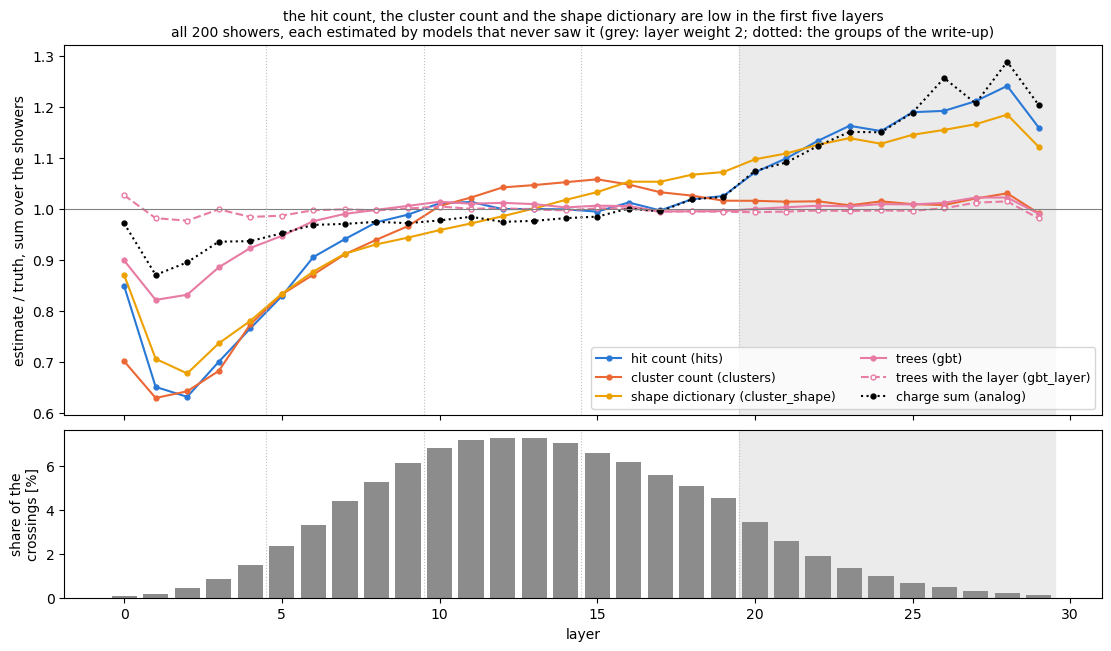

layer                  0     1     2     3     4     5     6     7     8     9    10    11    12    13    14
hits                0.85  0.65  0.63  0.70  0.77  0.83  0.91  0.94  0.97  0.99  1.01  1.01  1.00  1.00  1.00
clusters            0.70  0.63  0.64  0.68  0.77  0.83  0.87  0.91  0.94  0.97  1.01  1.02  1.04  1.05  1.05
cluster_shape       0.87  0.71  0.68  0.74  0.78  0.83  0.88  0.91  0.93  0.94  0.96  0.97  0.99  1.00  1.02
gbt                 0.90  0.82  0.83  0.89  0.92  0.95  0.98  0.99  1.00  1.01  1.01  1.01  1.01  1.01  1.00
gbt_layer           1.03  0.98  0.98  1.00  0.98  0.99  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
analog              0.97  0.87  0.90  0.94  0.94  0.95  0.97  0.97  0.97  0.97  0.98  0.98  0.97  0.98  0.98
layer                 15    16    17    18    19    20    21    22    23    24    25    26    27    28    29
hits                0.99  1.01  1.00  1.02  1.03  1.07  1.10  1.13  1.16  1.15  1.19  1.19  1.21  1.24  1.16
clusters           

In [12]:
TRUE_L = np.bincount(D1['layer'], D1['n_frac'], N_LAYERS)
RATIO_L = {nm: np.bincount(D1['layer'], P1[nm], N_LAYERS) / TRUE_L for nm in NAMES}
W64 = WRITEUP['section_6_4_depth']
GROUPS = W64['groups']
fig, axs = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]},
                        constrained_layout=True)
for nm in NAMES:
    axs[0].plot(L, RATIO_L[nm], STYLE[nm], marker='o', ms=3.5, color=COLOUR[nm], label=LABEL[nm],
                mfc='white' if nm == 'gbt_layer' else COLOUR[nm])
axs[0].axhline(1, color='0.5', lw=0.8)
for ax in axs:
    for a_, _ in GROUPS[1:]:
        ax.axvline(a_ - 0.5, color='0.75', lw=0.8, ls=':')
    ax.axvspan(W_FROM - 0.5, N_LAYERS - 0.5, color='0.92', zorder=0)
axs[0].set_ylabel('estimate / truth, sum over the showers')
axs[0].set_title(f'the hit count, the cluster count and the shape dictionary are low in the first five layers\n'
                 f'all {N_SHOWERS} showers, each estimated by models that never saw it '
                 f'(grey: layer weight {W_VALUE:g}; dotted: the groups of the write-up)', fontsize=10)
axs[0].legend(fontsize=9, ncol=2, loc='lower right')
axs[1].bar(L, 100 * TRUE_L / TRUE_L.sum(), color='0.55', width=0.8)
axs[1].set_ylabel('share of the\ncrossings [%]')
axs[1].set_xlabel('layer')
plt.show()
for part in (L[:15], L[15:]):
    print("layer             " + ''.join(f"{l:6d}" for l in part))
    for nm in NAMES:
        print(f"{nm:18s}" + ''.join(f"{x:6.2f}" for x in RATIO_L[nm][part]))

**In the groups of the write-up.** Section 6.4 of the write-up gives the same ratio in five groups
of layers, together with the share of the crossings and the hit pixels per crossing in each group.
Here every one of the 200 showers is estimated by models that never saw it, as in the write-up, so
the two can be compared number by number: the write-up's rows are printed under ours. Appendix A
checks them and sets notebook 11's 40 test showers beside them.

In [13]:
grp = np.zeros(N_LAYERS, int)
for g, (a_, b_) in enumerate(GROUPS):
    grp[a_:b_ + 1] = g
nG = len(GROUPS)
g_all = grp[D1['layer']]
T_G = np.bincount(g_all, D1['n_frac'], nG)
SHARE_G = T_G / T_G.sum()
HPC_G = np.bincount(g_all, D1['n_hits'], nG) / T_G
GROUP1 = {nm: np.bincount(g_all, P1[nm], nG) / T_G for nm in NAMES}
print("layers                  " + ''.join(f"{f'{a_} to {b_}':>10s}" for a_, b_ in GROUPS))
print("share of the crossings  " + ''.join(f"{100 * x:9.2f}%" for x in SHARE_G))
print("  write-up              " + ''.join(f"{x:9.1f}%" for x in W64['share']))
print("hit pixels per crossing " + ''.join(f"{x:10.3f}" for x in HPC_G))
print("  write-up              " + ''.join(f"{x:10.1f}" for x in W64['hits_per_crossing']))
print("estimate / truth")
for nm in NAMES:
    print(f"  {nm:22s}" + ''.join(f"{x:10.4f}" for x in GROUP1[nm]))
    if nm in W64['ratio']:
        print(f"    write-up              " + ''.join(f"{x:10.2f}" for x in W64['ratio'][nm]))
print("appendix A checks the two rows without a fit and the ratios of the tables against the write-up's "
      "printed digits")

layers                      0 to 4    5 to 9  10 to 14  15 to 19  20 to 29
share of the crossings       3.07%    21.43%    35.52%    27.95%    12.04%
  write-up                    3.1%     21.4%     35.5%     27.9%     12.0%
hit pixels per crossing      2.905     3.486     4.020     4.353     4.700
  write-up                     2.9       3.5       4.0       4.4       4.7
estimate / truth
  hits                      0.7232    0.9447    1.0045    1.0084    1.1228
    write-up                    0.72      0.94      1.00      1.01      1.12
  clusters                  0.7185    0.9188    1.0340    1.0380    1.0137
    write-up                    0.72      0.92      1.03      1.04      1.01
  cluster_shape             0.7511    0.9115    0.9869    1.0541    1.1198
  gbt                       0.8927    0.9896    1.0096    1.0001    1.0048
    write-up                    0.89      0.99      1.01      1.00      1.00
  gbt_layer                 0.9883    0.9974    1.0004    0.9976    0.9960
  

- `hits`, `clusters` and `cluster_shape` are low in the first five layers: 0.72, 0.72 and 0.75.
  In layers 20 to 29 `hits` and `cluster_shape` are 1.12. Layer by layer (figure above) `hits`
  goes from 0.63 in layer 2 to 1.24 in layer 28.
- `gbt` is 0.89 in layers 0 to 4 and between 0.989 and 1.010 in the groups from layer 5 on (layer
  by layer 0.95 at layer 5 and 0.98 at layer 6). `gbt_layer`, which also reads the layer number,
  stays between 0.988 and 1.001.
- Hit pixels per crossing rise with depth, from 2.9 in layers 0 to 4 to 4.7 in layers 20 to 29.
  A table gives the same count to the same hit map in every layer, the count of a crossing that
  lights an average number of pixels. So it counts too few in front, where a crossing lights fewer
  pixels than that, and too many behind, where it lights more: `hits` rises from 0.72 to 1.12.

*Try it:* set `DISPLAY` (configuration cell) to another shower of batch 0, any of 0 to 19, and
compare its ratios per layer with those of all 200 showers.

## 4. The shower total

The total of a shower is the sum over all its stored reticles, with and without the layer weights.
`mc.event_totals` gives, for one estimator, the spread of its totals over the showers, the spread
of the true totals, and the mean and spread of their ratio; `mc.event_references` gives the
spreads of the summed hit pixels and of the summed charge (`q_sum`, before noise). We make every
total by hand with `np.bincount` on `super_evt`; appendix A checks that both functions give the
same numbers.

In [14]:
NS1 = D1['n_super_events']


def totals(D, x, weighted):
    # per stack: the sum over its stored reticles of x, times the layer weight if weighted
    return np.bincount(D['super_evt'], x * D['layer_w'] if weighted else x, D['n_super_events'])


def spread(t):
    # standard deviation over the stacks / mean, ddof 1, as mc._spread
    return t.std(ddof=1) / t.mean()


QUANT = {'true crossings': D1['n_frac'], 'hit pixels': D1['n_hits'].astype(float), 'charge': D1['q_sum'],
         **{nm: P1[nm] for nm in NAMES}}
TOT = {(k, w): totals(D1, x, w) for k, x in QUANT.items() for w in (True, False)}
ROW = {}
for k in QUANT:
    ROW[k] = {'spread_w': spread(TOT[k, True]), 'spread_u': spread(TOT[k, False])}
    if k in NAMES:
        for w, key in ((True, 'w'), (False, 'u')):
            r = TOT[k, w] / TOT['true crossings', w]
            ROW[k][f'ratio_{key}'], ROW[k][f'ratio_sd_{key}'] = r.mean(), r.std(ddof=1)

print(f"{NS1} showers; mean true total {TOT['true crossings', False].mean():,.0f} crossings unweighted, "
      f"{TOT['true crossings', True].mean():,.0f} weighted")
print("appendix A checks these totals against mc.event_totals and mc.event_references")

200 showers; mean true total 4,027 crossings unweighted, 4,512 weighted
appendix A checks these totals against mc.event_totals and mc.event_references


**The table of the write-up's section 6.2**, rebuilt: the spread of each total, weighted and
unweighted, and the ratio of the weighted totals, mean +- spread over the showers. Beside each
number, the write-up's.

In [15]:
W62 = WRITEUP['section_6_2']
print(f"{'total of':16s}{'spread, weighted':>22s}{'spread, unweighted':>22s}{'ratio (weighted): mean +- spread':>40s}"
      f"{'error of':>11s}")
print(f"{'':16s}{'here':>12s}{'write-up':>10s}{'here':>12s}{'write-up':>10s}{'here':>22s}{'write-up':>18s}"
      f"{'the mean':>11s}")
for k in QUANT:
    r_, doc = ROW[k], W62[k]
    line = f"{k:16s}{100 * r_['spread_w']:11.2f}%{doc[0]:9.1f}%{100 * r_['spread_u']:11.2f}%"
    line += f"{doc[1]:9.1f}%" if len(doc) > 1 else f"{'':10s}"
    if k in NAMES:
        line += f"{r_['ratio_w']:13.4f} +- {r_['ratio_sd_w']:.4f}"
        line += f"{doc[2]:10.3f} +- {doc[3]:.3f}" if len(doc) > 2 else f"{'':18s}"
        line += f"{100 * r_['ratio_sd_w'] / np.sqrt(NS1):10.2f}%"
    print(line)
print(f"error of the mean: the part from the showers (fitted tables and models held fixed), the spread of the ratio / "
      f"sqrt({NS1}), in per cent")
print("mean ratio minus one, in errors of the mean: " + ', '.join(
    f"{nm} {round((ROW[nm]['ratio_w'] - 1) / (ROW[nm]['ratio_sd_w'] / np.sqrt(NS1)), 1) + 0.0:+.1f}" for nm in NAMES))
print("appendix A checks the numbers of this table against the write-up's printed digits")

total of              spread, weighted    spread, unweighted        ratio (weighted): mean +- spread   error of
                        here  write-up        here  write-up                  here          write-up   the mean
true crossings         2.16%      2.2%       6.98%      7.0%
hit pixels             3.81%      3.8%       8.17%      8.2%
charge                 3.41%      3.4%       7.79%      7.8%
hits                   3.92%      3.9%       8.50%      8.5%       1.0116 +- 0.0271     1.012 +- 0.027      0.19%
clusters               2.82%      2.8%       7.28%      7.3%       1.0000 +- 0.0168     1.000 +- 0.017      0.12%
cluster_shape          2.97%      3.0%       7.73%      7.7%       1.0113 +- 0.0161     1.011 +- 0.016      0.11%
gbt                    2.60%      2.6%       7.31%      7.3%       0.9991 +- 0.0109     0.999 +- 0.011      0.08%
gbt_layer              2.92%      2.9%       7.84%                 0.9977 +- 0.0132                        0.09%
analog                 3

- Every number of the write-up's table is rebuilt except its network rows (this notebook trains
  no network) and its `hits_clusters` row, an estimator (a table on the hit pixels and the
  clusters together) that notebooks 11 and 12 leave out. Appendix A checks the tables against its
  printed digits and prints the trees beside it.
- With the weights the true total spreads by 2.16% over the showers, without them by 6.98%. The
  7% is in the true total itself, before any counting. The write-up (section 6.2) gives the
  reason for the weights: without them the spread is set by how deep the shower develops, not by
  the counting. A late shower puts more of its crossings behind the thick plates, where one layer
  stands for twice the tungsten, so counted with weight 1 it comes out short, and the spread
  between showers is then mostly how deep they developed. The drawing below sketches this with two
  made-up depth profiles, an early and a late shower, over the plates of section 1.
- Every estimated total spreads more than the true one: `gbt` 2.60%, `clusters` 2.82%, `gbt_layer`
  2.92%, `cluster_shape` 2.97%, `analog` 3.33%, `hits` 3.92%. The summed charge (3.41%) and the
  summed hit pixels (3.81%) spread more than `gbt`.
- The ratio of `hits`, `cluster_shape` and `analog` is 1.0113 to 1.0124, several times the error
  of its mean (0.11 to 0.19%) above one. `clusters` (1.0000) is within that error of one, `gbt`
  (0.9991) 1.1 errors below it.

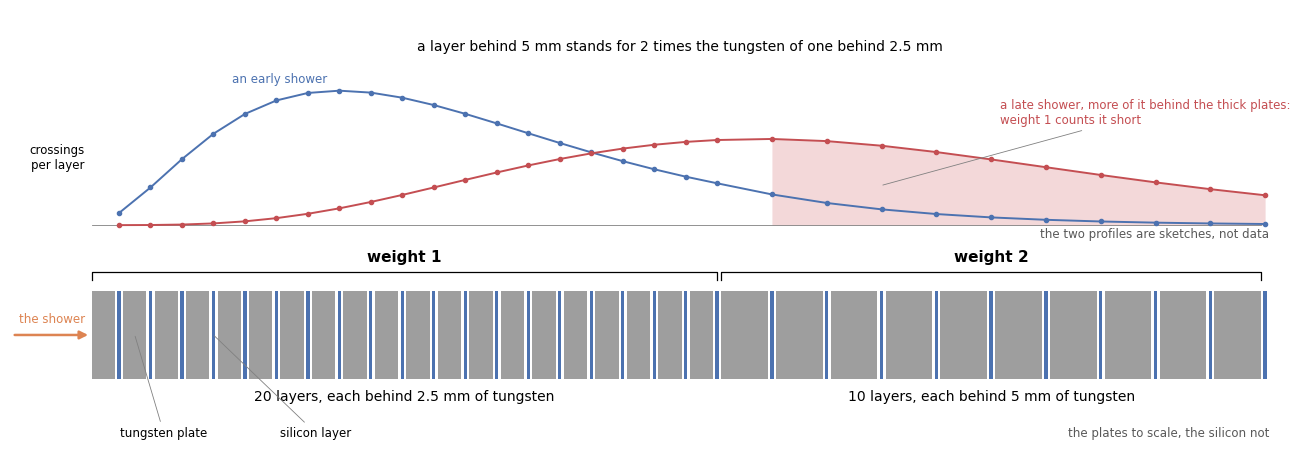

In [16]:
sketches.layer_weights(plates[0][0], plates[0][1], plates[1][0], plates[1][1], profiles=True)
plt.show()

**Shower by shower.** Left: the weighted total of `gbt` and of the hit-count table `hits` against
the true weighted total, one point per shower. Right: the distribution of their ratio to the truth.

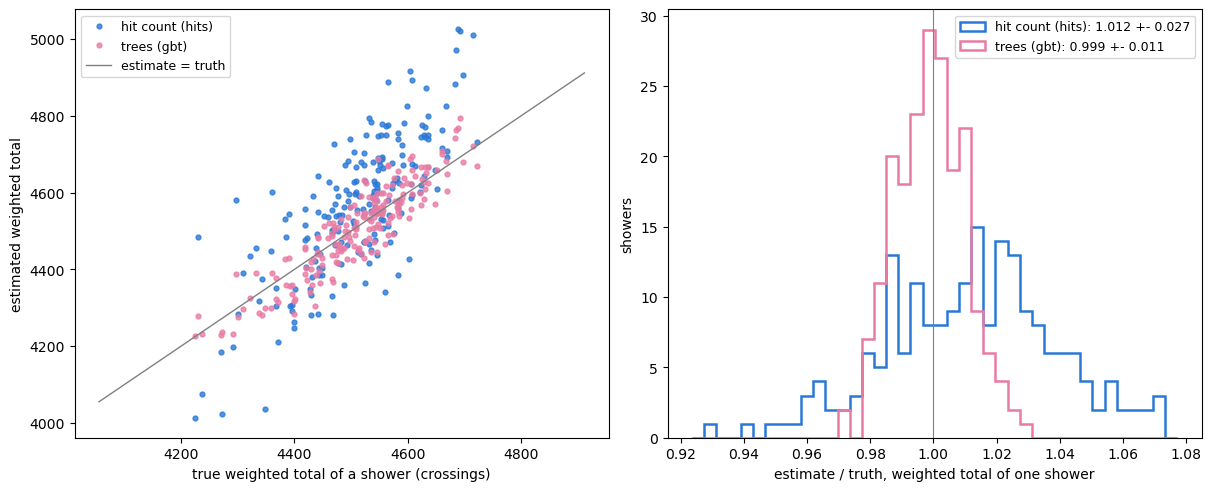

hits: the ratio ranges from 0.929 to 1.072; correlation of the estimated with the true weighted totals 0.762
gbt: the ratio ranges from 0.970 to 1.031; correlation of the estimated with the true weighted totals 0.911


In [17]:
tw = TOT['true crossings', True]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for nm in ('hits', 'gbt'):
    axs[0].plot(tw, TOT[nm, True], 'o', ms=3.5, color=COLOUR[nm], alpha=0.8, label=LABEL[nm])
lim = np.array([tw.min(), tw.max()]) * np.array([0.96, 1.04])
axs[0].plot(lim, lim, color='0.5', lw=1, label='estimate = truth')
axs[0].set_xlabel('true weighted total of a shower (crossings)')
axs[0].set_ylabel('estimated weighted total')
axs[0].legend(fontsize=9)
rr = {nm: TOT[nm, True] / tw for nm in ('hits', 'gbt')}
edges = np.linspace(min(r.min() for r in rr.values()) - 0.005, max(r.max() for r in rr.values()) + 0.005, 41)
for nm, r in rr.items():
    axs[1].hist(r, bins=edges, histtype='step', lw=1.8, color=COLOUR[nm],
                label=f"{LABEL[nm]}: {r.mean():.3f} +- {r.std(ddof=1):.3f}")
axs[1].axvline(1, color='0.5', lw=0.8)
axs[1].set_xlabel('estimate / truth, weighted total of one shower')
axs[1].set_ylabel('showers')
axs[1].legend(fontsize=9)
plt.show()
for nm, r in rr.items():
    print(f"{nm}: the ratio ranges from {r.min():.3f} to {r.max():.3f}; correlation of the estimated with the true "
          f"weighted totals {np.corrcoef(TOT[nm, True], tw)[0, 1]:.3f}")

Shower by shower the `gbt` total stays between 0.970 and 1.031 of the truth and follows it closely
(correlation 0.911). The hit-count table ranges from 0.929 to 1.072 (correlation 0.762).

In [18]:
print(f"ratio of the unweighted totals, mean over the showers (write-up: {W62['unweighted_ratio']} for every estimator):")
print('  ' + ', '.join(f"{nm} {ROW[nm]['ratio_u']:.4f}" for nm in NAMES))
empty = D1['n_hits'] == 0
MISSING = D1['n_frac'][empty].sum() / D1['n_frac'].sum()
MISSING_SH = np.bincount(D1['super_evt'][empty], D1['n_frac'][empty], NS1) / TOT['true crossings', False]
print(f"share of n_frac in reticles holding charge but no hit pixel: {MISSING:.3%} of all crossings "
      f"(per shower {MISSING_SH.min():.3%} to {MISSING_SH.max():.3%}); the write-up: {W62['missing']}%")
zero = [nm for nm in NAMES if np.any(P1[nm][empty] != 0)]
print(f"{int(empty.sum()):,} of the {D1['n']:,} stored reticles have no hit pixel. Estimators giving some of them more "
      f"than 0: {', '.join(zero) if zero else 'none'}" +
      ''.join(f"; {nm} gives them {P1[nm][empty].sum() / D1['n_frac'].sum():.3%} of the true total" for nm in zero))

ratio of the unweighted totals, mean over the showers (write-up: 0.998 for every estimator):
  hits 0.9975, clusters 0.9983, cluster_shape 0.9978, gbt 0.9983, gbt_layer 0.9974, analog 0.9990
share of n_frac in reticles holding charge but no hit pixel: 0.168% of all crossings (per shower 0.084% to 0.315%); the write-up: 0.2%
28,818 of the 600,628 stored reticles have no hit pixel. Estimators giving some of them more than 0: analog; analog gives them 0.146% of the true total


- Without the weights the six ratios lie between 0.9974 and 0.9990. The write-up gives 0.998 for
  every estimator; to three digits that holds for four of them, while `gbt_layer` gives 0.997
  and `analog` 0.999.
- 0.168% of the crossings sit in reticles that hold charge but no hit pixel (0.084 to 0.315% per
  shower). The binary estimators give these reticles 0. `analog`, which reads the charge, gives
  them 0.146% of the true total.
- With the weights the ratios of `hits`, `cluster_shape` and `analog` rise above one (`clusters`
  stays at 1.0000). The weighted sum counts layers 20 to 29 twice, and there `hits`,
  `cluster_shape` and `analog` are 1.12 (section 3).

**How well are the spreads known?** A spread from 200 showers has a statistical error of about
1 / sqrt(2 x 199) of its value. The rows of the table share the showers, so their differences are
known better than that. We resample the 200 showers with replacement (a bootstrap, 2000 times) and
take the standard deviation of each difference of weighted spreads, in percentage points.

In [19]:
print(f"statistical error of a spread from {NS1} showers: 1 / sqrt(2 x {NS1 - 1}) = {1 / np.sqrt(2 * (NS1 - 1)):.1%} of its value, "
      f"for example {100 * ROW['true crossings']['spread_w']:.2f}% +- {100 * ROW['true crossings']['spread_w'] / np.sqrt(2 * (NS1 - 1)):.2f}% "
      "for the true weighted total")
boot = np.random.default_rng(SEED).integers(0, NS1, size=(2000, NS1))   # 2000 resamples of the showers


def spread_b(t):
    s = t[boot]
    return s.std(axis=1, ddof=1) / s.mean(axis=1)


BOOT = {}
print(f"\n{'difference of weighted spreads':34s}{'here':>16s}{'write-up':>16s}  within 0.05 points / 30%")
for a_, b_, doc, doc_sd in W62['bootstrap']:
    d0 = 100 * (ROW[a_]['spread_w'] - ROW[b_]['spread_w'])
    sd = (100 * (spread_b(TOT[a_, True]) - spread_b(TOT[b_, True]))).std(ddof=1)
    BOOT[a_, b_] = (d0, sd)
    ok = abs(d0 - doc) <= 0.05 and abs(sd - doc_sd) <= 0.3 * doc_sd
    print(f"{a_ + ' minus ' + b_:34s}{d0:9.2f} +- {sd:.2f}{doc:9.2f} +- {doc_sd:.2f}  {ok}")
a_, b_ = 'hit pixels', 'charge'
d0 = 100 * (ROW[a_]['spread_w'] - ROW[b_]['spread_w'])
sd = (100 * (spread_b(TOT[a_, True]) - spread_b(TOT[b_, True]))).std(ddof=1)
print(f"{a_ + ' minus ' + b_:34s}{d0:9.2f} +- {sd:.2f}  (not in the write-up)")
print("each difference of the write-up involves gbt: printed, not asserted")

statistical error of a spread from 200 showers: 1 / sqrt(2 x 199) = 5.0% of its value, for example 2.16% +- 0.11% for the true weighted total

difference of weighted spreads                here        write-up  within 0.05 points / 30%
gbt minus true crossings               0.44 +- 0.07     0.44 +- 0.07  True
hit pixels minus gbt                   1.21 +- 0.16     1.21 +- 0.15  True
charge minus gbt                       0.81 +- 0.14     0.81 +- 0.14  True
clusters minus gbt                     0.22 +- 0.10     0.22 +- 0.10  True
gbt_layer minus gbt                    0.32 +- 0.06     0.32 +- 0.06  True
hit pixels minus charge                0.40 +- 0.10  (not in the write-up)
each difference of the write-up involves gbt: printed, not asserted


- All five differences agree with the write-up's: within 0.05 points, and their errors within
  30% of the write-up's.
- The truth, `gbt`, the summed charge and the summed hit pixels are separated by several
  standard deviations: `gbt` minus truth 0.44 +- 0.07, charge minus `gbt` 0.81 +- 0.14, hit
  pixels minus `gbt` 1.21 +- 0.16, hit pixels minus charge 0.40 +- 0.10 points.
- `clusters` minus `gbt` is 0.22 +- 0.10 points, about two standard deviations.
- `gbt_layer` minus `gbt` is 0.32 +- 0.06 points: with the layer number the tree's shower total
  spreads more, although its ratio is flat in depth (section 3).

**The count as an 8-bit number.** The edge logic would send each count as a number of a few bits.
Eight bits in steps of 0.25 crossings reach 63.75; in steps of 1 they reach 255. We round each
reticle's `gbt` estimate to these steps (`ROUND_STEPS`), clip it at the largest value, and form the
totals again.

In [20]:
gbt = P1['gbt']
W_R = W62['rounding']
ROUND = {'none': gbt}
for step in ROUND_STEPS:
    ROUND[step] = np.minimum(np.round(gbt / step) * step, 255 * step)
print(f"{'gbt estimate per reticle':28s}{'weighted spread':>17s}{'write-up':>10s}{'ratio (weighted)':>18s}{'total / unrounded':>19s}")
for key, est in ROUND.items():
    sp_ = spread(totals(D1, est, True))
    r_ = totals(D1, est, True) / TOT['true crossings', True]
    scale = totals(D1, est, True).sum() / TOT['gbt', True].sum()
    ROUND_ROW = (sp_, r_.mean(), scale)
    label = 'not rounded' if key == 'none' else f"steps of {key:g}, at most {255 * key:g}"
    doc_ = f"{W_R[key]:9.2f}%" if key in W_R else f"{'-':>9s} "      # the write-up gives 'none', 0.25 and 1
    print(f"{label:28s}{100 * sp_:16.2f}%{doc_}{r_.mean():12.4f} +- {r_.std(ddof=1):.4f}{scale:12.4f}")
    if key == 0.25:
        R025 = ROUND_ROW
    elif key == 1.0:
        R1_ = ROUND_ROW
d025 = 100 * (R025[0] - spread(TOT['gbt', True]))
print(f"steps of 0.25 change the weighted spread by {d025:+.3f} points (write-up {W_R[0.25] - W_R['none']:+.2f}); "
      f"the 0.25 case within 0.05 points of the write-up's {W_R[0.25]}%: {abs(100 * R025[0] - W_R[0.25]) <= 0.05}; "
      "printed, not asserted (gbt)")
print(f"steps of 1 shift the scale of the total by {100 * (R1_[2] - 1):+.1f}% (write-up: {W_R['shift_1']}%)")
moved = (ROUND[1.0] - gbt) * D1['layer_w']
whole = (gbt * D1['layer_w']).sum()
hit = D1['n_hits'] > 0
print(f"steps of 1, weighted: reticles rounded up add {moved[moved > 0].sum() / whole:+.1%} to the total "
      f"({moved[(gbt >= 0.5) & (gbt < 1)].sum() / whole:+.1%} from those whose gbt estimate lies in [0.5, 1)), those "
      f"rounded down {moved[moved < 0].sum() / whole:+.1%}; {np.mean(np.round(gbt[hit]) == 0):.1%} of the reticles with "
      f"a hit pixel become 0, {np.mean(np.round(gbt[hit]) == 1):.1%} become 1")
HALF_UP = np.mean((gbt[hit] >= 0.5) & (gbt[hit] < 1))    # the share of the reticles with a hit pixel in [0.5, 1)
print(f"gbt estimates of reticles with a hit pixel: {HALF_UP:.1%} lie in [0.5, 1), "
      f"{np.mean((gbt[hit] >= 1) & (gbt[hit] < 1.5)):.1%} in [1, 1.5)")

gbt estimate per reticle      weighted spread  write-up  ratio (weighted)  total / unrounded
not rounded                             2.60%     2.60%      0.9991 +- 0.0109      1.0000
steps of 0.25, at most 63.75            2.63%     2.62%      0.9964 +- 0.0117      0.9972
steps of 1, at most 255                 2.67%     2.67%      1.0535 +- 0.0122      1.0545
steps of 0.25 change the weighted spread by +0.028 points (write-up +0.02); the 0.25 case within 0.05 points of the write-up's 2.62%: True; printed, not asserted (gbt)
steps of 1 shift the scale of the total by +5.4% (write-up: 5%)
steps of 1, weighted: reticles rounded up add +11.4% to the total (+9.3% from those whose gbt estimate lies in [0.5, 1)), those rounded down -5.9%; 11.1% of the reticles with a hit pixel become 0, 71.3% become 1
gbt estimates of reticles with a hit pixel: 46.8% lie in [0.5, 1), 24.5% in [1, 1.5)


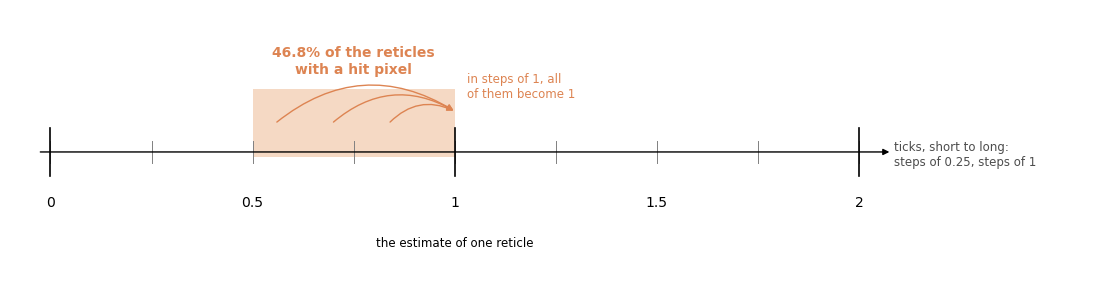

In [21]:
sketches.rounding_steps(ROUND_STEPS, HALF_UP)
plt.show()

The drawing puts the steps on a number line: in steps of 1, every estimate in [0.5, 1) rounds up
to 1.

- Steps of 0.25 barely change the spread, 2.60% to 2.63% (the write-up: 2.62%), and scale the
  total by 0.9972.
- Steps of 1 give 2.67% and scale the total by 1.0545. Rounding up adds 11.4% (9.3% from the
  reticles whose `gbt` estimate lies between 0.5 and 1, 46.8% of those with a hit pixel, which all
  become 1), and rounding down removes 5.9%.

*Try it:* add a step of 0.5 to `ROUND_STEPS` (configuration cell): 8 bits then reach 127.5
crossings.

## 5. Density: does the calibration carry over to denser reticles?

Stacks of K showers raise the density of the reticles. We load the three stacked files and read
all four files out together, as the write-up does, so that every file gets the readout noise of
the write-up's run (file i from the seed (SEED, i)) and the blocks line up: a stack of block f
holds only showers of block f (`mc.super_event_fold`; we check it from the charge of every stack).
With the same noise as the write-up's run, its numbers can be compared with ours digit by digit.

In [22]:
TAGS = ('K1', 'K2', 'K4', 'K8')
RAW = {'K1': R1}
for t in TAGS[1:]:
    RAW[t] = mc.load_reticles(need(f'ret_{t}.npz'))
t0 = time.time()
DL, EV_BLOCK_4 = mc.prepare([RAW[t] for t in TAGS], list(TAGS), THRESHOLD, NOISE, SEED, N_BLOCKS)
print(f"mc.prepare of the four files: {time.time() - t0:.0f} s")
same = all(np.array_equal(DL[0][k], D1[k]) for k in ('feat', 'n_frac', 'super_evt', 'fold', 'layer', 'q_sum'))
assert same and np.array_equal(EV_BLOCK_4, EV_BLOCK), "the single showers read out with the stacks differ from section 1"
print("check: read out together with the stacks, the single showers give the same 49 numbers per reticle, truths and "
      "blocks as in section 1")
DL[0] = D1                                        # the same arrays: keep section 1's
DS = dict(zip(TAGS, DL))
for R in RAW.values():
    R.pop('img', None)                            # the charge images are not needed further
del img
KS = [DS[t]['overlay'] for t in TAGS]
Q_SHOWER = np.bincount(D1['super_evt'], D1['q_sum'], N_SHOWERS)      # the charge of every single shower
Q_DEV = {}
for t, D in DS.items():
    K, n_s = D['overlay'], D['n_super_events']
    D['layer_w'] = mc.layer_weights(mc.parse_layer_weights(LAYER_WEIGHTS), D['layer'])
    assert n_s * K == N_SHOWERS, f"{t}: {n_s} stacks of {K} showers"
    q_stack = np.bincount(D['super_evt'], D['q_sum'], n_s)
    q_from = np.bincount(np.arange(N_SHOWERS) // K, Q_SHOWER, n_s)   # stack s: showers s K to s K + K - 1
    Q_DEV[t] = np.max(np.abs(q_stack / q_from - 1))
    assert Q_DEV[t] <= 1e-9, f"{t}: the charge of a stack is not that of {K} consecutive showers ({Q_DEV[t]:.1e})"
    assert BLOCK % K == 0, f"{t}: {K} does not divide the {BLOCK} showers of a block"
    assert np.array_equal(RAW[t]['part_evt'] // K, D['super_evt'][RAW[t]['part_reticle']]), \
        f"{t}: a particle row lies in a reticle of another stack"
print("check: in every file the charge of each stack is that of K consecutive showers (largest relative difference "
      + ', '.join(f"{t} {d:.0e}" for t, d in Q_DEV.items()) + f"), and K divides the {BLOCK} showers of a block, so a "
      "stack holds showers of one block; every particle row sits in a reticle of its stack (as mc.prepare requires)")
print(f"\n{'file':6s}{'stacks':>8s}{'reticles':>12s}{'crossings per stack':>21s}{'in reticles above 20':>22s}{'densest reticle':>17s}")
for t, D in DS.items():
    nf = D['n_frac']
    print(f"{t:6s}{D['n_super_events']:8d}{D['n']:12,d}{nf.sum() / D['n_super_events']:21,.0f}"
          f"{nf[np.rint(nf) > 20].sum() / nf.sum():21.1%}{nf.max():17.1f}")

mc.prepare of the four files: 14 s
check: read out together with the stacks, the single showers give the same 49 numbers per reticle, truths and blocks as in section 1
check: in every file the charge of each stack is that of K consecutive showers (largest relative difference K1 0e+00, K2 3e-11, K4 3e-11, K8 1e-11), and K divides the 40 showers of a block, so a stack holds showers of one block; every particle row sits in a reticle of its stack (as mc.prepare requires)

file    stacks    reticles  crossings per stack  in reticles above 20  densest reticle
K1         200     600,628                4,027                12.5%             95.7
K2         100     521,996                8,054                18.5%            172.5
K4          50     441,782               16,107                24.5%            262.4
K8          25     365,407               32,214                34.8%            441.4


From K = 1 to K = 8 the share of the crossings in reticles above 20 crossings rises from 12.5% to
34.8%, and the densest reticle from 95.7 to 441.4 crossings.

**Three fits.** Each is a five-block refit, so a stack is always estimated by models that never saw
its showers:

- (a) trained on single showers (K = 1) and applied to every K: the calibration of section 2 used
  on denser reticles;
- (b) trained on the mix of all four files and applied to each: the write-up's first table in
  section 6.4;
- (c) trained on K = 1 and 2 and applied to K = 4 and 8, densities it never saw: the write-up's
  second table.

For each, the ratio of the weighted totals per K (mean over the stacks). The drawing after the
fits marks the files each fit is trained on and those it is applied to.

In [23]:
FIT_SETUP = {'a': (['K1'], list(TAGS)), 'b': (list(TAGS), list(TAGS)), 'c': (['K1', 'K2'], ['K4', 'K8'])}
FIT_TITLE = {'a': '(a) trained on K = 1', 'b': '(b) trained on K = 1, 2, 4, 8', 'c': '(c) trained on K = 1, 2'}
FIT = {}
for f, (tr, ev) in FIT_SETUP.items():
    t0 = time.time()
    FIT[f] = mc.crossfit(DL, 'n_frac', NAMES, N_BLOCKS, tr, ev, n_events=N_SHOWERS)
    T_FIT[f"fit ({f}): trained on {'+'.join(tr)}, applied to {'+'.join(ev)}"] = time.time() - t0
    n_tr = sum(DS[t]['n'] for t in tr)
    print(f"fit ({f}): trained on {', '.join(tr)} ({n_tr:,} reticles; each block's fit uses the four fifths outside the "
          f"block), applied to {', '.join(ev)}: {time.time() - t0:.0f} s")
assert all(np.array_equal(FIT['a']['K1'][nm], P1[nm]) for nm in NAMES), "fit (a) on the single showers differs from section 2"
print("check: on the single showers fit (a) gives exactly the estimates of section 2: the same models")
RATIO_K = {f: {nm: {t: mc.event_totals(DS[t], FIT[f][t][nm], DS[t]['n_frac'])['weighted']['ratio_mean']
                    for t in FIT[f]} for nm in NAMES} for f in FIT}
for f in FIT:
    tags_ = list(FIT[f])
    print(f"\n{FIT_TITLE[f]}: ratio of the weighted totals")
    print(f"{'':16s}" + ''.join(f"{'K = ' + t[1:]:>10s}" for t in tags_))
    for nm in NAMES:
        print(f"{nm:16s}" + ''.join(f"{RATIO_K[f][nm][t]:10.4f}" for t in tags_))
print("\nappendix A checks fits (b) and (c) against the write-up's two tables of section 6.4")

fit (a): trained on K1 (600,628 reticles; each block's fit uses the four fifths outside the block), applied to K1, K2, K4, K8: 173 s


fit (b): trained on K1, K2, K4, K8 (1,929,813 reticles; each block's fit uses the four fifths outside the block), applied to K1, K2, K4, K8: 173 s


fit (c): trained on K1, K2 (1,122,624 reticles; each block's fit uses the four fifths outside the block), applied to K4, K8: 148 s
check: on the single showers fit (a) gives exactly the estimates of section 2: the same models



(a) trained on K = 1: ratio of the weighted totals
                     K = 1     K = 2     K = 4     K = 8
hits                1.0116    1.0734    1.1775    1.3125
clusters            1.0000    0.9833    0.9368    0.8541
cluster_shape       1.0113    1.0175    1.0398    1.0968
gbt                 0.9991    1.0110    1.0153    1.0248
gbt_layer           0.9977    1.0090    1.0101    1.0167
analog              1.0124    1.0293    1.0693    1.1271

(b) trained on K = 1, 2, 4, 8: ratio of the weighted totals
                     K = 1     K = 2     K = 4     K = 8
hits                0.9201    0.9458    1.0152    1.1381
clusters            1.0628    1.0496    1.0027    0.9174
cluster_shape       0.9821    0.9830    1.0024    1.0682
gbt                 0.9688    0.9837    1.0021    1.0397
gbt_layer           0.9674    0.9825    1.0024    1.0418
analog              0.9701    0.9820    1.0117    1.0590

(c) trained on K = 1, 2: ratio of the weighted totals
                     K = 4     K =

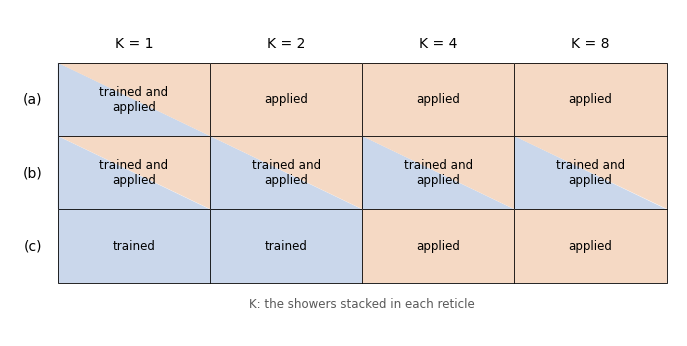

In [24]:
FIT_GRID = {f'({f})': {DS[t]['overlay']: 'both' if t in tr and t in ev else 'trained' if t in tr else 'applied'
                       for t in TAGS if t in tr or t in ev} for f, (tr, ev) in FIT_SETUP.items()}
sketches.fit_grid(FIT_GRID, ks=tuple(KS))
plt.show()

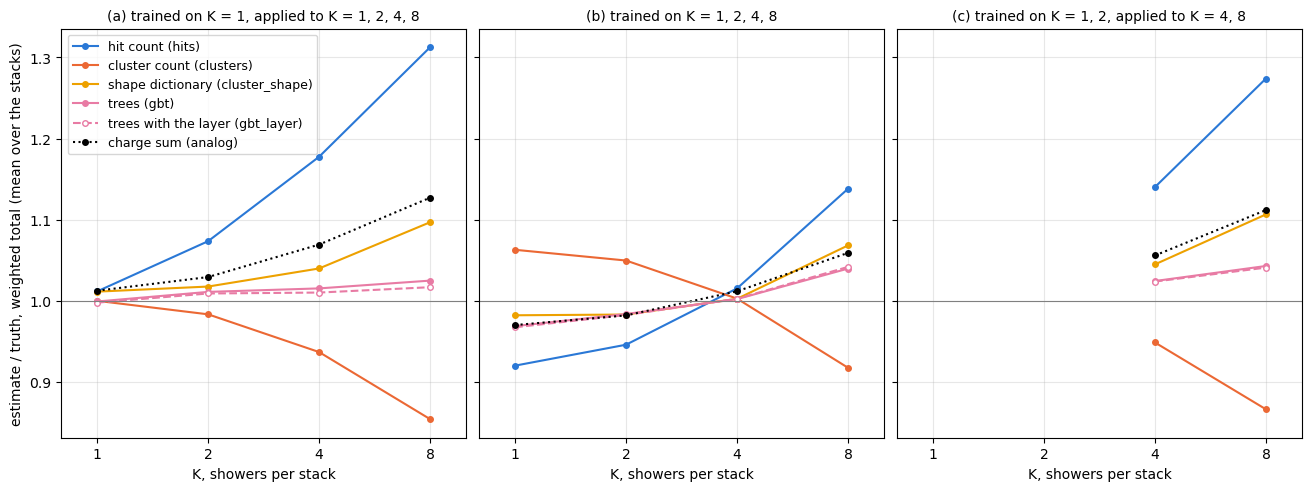

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True, constrained_layout=True)
for ax, f in zip(axs, FIT):
    tags_ = list(FIT[f])
    k_ = [DS[t]['overlay'] for t in tags_]
    for nm in NAMES:
        ax.plot(k_, [RATIO_K[f][nm][t] for t in tags_], STYLE[nm], marker='o', ms=4, color=COLOUR[nm], label=LABEL[nm],
                mfc='white' if nm == 'gbt_layer' else COLOUR[nm])
    ax.axhline(1, color='0.5', lw=0.8)
    ax.set_xscale('log', base=2)
    ax.set_xticks(KS)
    ax.set_xticklabels([str(k) for k in KS])
    ax.set_xlim(0.8, 10)
    ax.set_xlabel('K, showers per stack')
    ax.set_title(FIT_TITLE[f] + ('' if f == 'b' else f", applied to K = {', '.join(t[1:] for t in tags_)}"), fontsize=10)
    ax.grid(alpha=0.3)
axs[0].set_ylabel('estimate / truth, weighted total (mean over the stacks)')
axs[0].legend(fontsize=9)
plt.show()

- Trained on single showers (a), the tables drift with the density. At K = 8 `hits` is 1.312,
  `analog` 1.127, `cluster_shape` 1.097 and `clusters` 0.854. The trees move less: `gbt` 1.025,
  `gbt_layer` 1.017.
- Trained on the mix (b), every estimator but `clusters` is low at K = 1 and high at K = 8:
  `hits` 0.920 to 1.138, `gbt` 0.969 to 1.040, `gbt_layer` 0.967 to 1.042. `clusters` goes the
  other way, 1.063 to 0.917. The tables give the write-up's first table of section 6.4 to its
  printed digits; `gbt` and `gbt_layer` agree within 0.002 (appendix A).
- Trained on K = 1 and 2 (c), the tables at K = 8 are a little closer to one than in (a): `hits`
  1.274 against 1.312, `clusters` 0.866 against 0.854, `analog` 1.112 against 1.127.
  `cluster_shape` and the trees are further off: `cluster_shape` 1.106, `gbt` 1.043, `gbt_layer`
  1.041.
- For `gbt`, the single showers alone (a) carry over to K = 8 better (1.025) than K = 1 and 2
  together (c, 1.043) or the mix (b, 1.040). We have not traced why.

**The spread per K.** A stack adds K showers, so the spread of its total falls with K. Below, the
spread of the true weighted total and of the `gbt` total of fit (b) at each K, with the statistical
error of a spread from that many stacks, 1 / sqrt(2 (n - 1)) of its value.

In [26]:
print(f"{'K':>3s}{'stacks':>8s}{'truth':>9s}{'write-up':>10s}{'truth at K = 1 / sqrt(K)':>26s}{'gbt, fit (b)':>14s}"
      f"{'statistical error':>19s}")
SPREAD_K = {}
for t, D in DS.items():
    e = mc.event_totals(D, FIT['b'][t]['gbt'], D['n_frac'])['weighted']
    SPREAD_K[t] = (e['spread_truth'], e['spread_est'])
for (t, D), doc in zip(DS.items(), WRITEUP['spread_truth_per_K']):
    K, n_ = D['overlay'], D['n_super_events']
    print(f"{K:3d}{n_:8d}{100 * SPREAD_K[t][0]:8.2f}%{doc:9.1f}%{100 * SPREAD_K['K1'][0] / np.sqrt(K):25.2f}%"
          f"{100 * SPREAD_K[t][1]:13.2f}%{1 / np.sqrt(2 * (n_ - 1)):18.1%}")

  K  stacks    truth  write-up  truth at K = 1 / sqrt(K)  gbt, fit (b)  statistical error
  1     200    2.16%      2.2%                     2.16%         2.69%              5.0%
  2     100    1.46%      1.5%                     1.53%         1.92%              7.1%
  4      50    1.07%      1.1%                     1.08%         1.48%             10.1%
  8      25    0.77%      0.8%                     0.76%         1.23%             14.4%


The true total spreads by 2.16, 1.46, 1.07 and 0.77% at K = 1, 2, 4 and 8, the write-up's 2.2,
1.5, 1.1 and 0.8%, and close to 2.16% / sqrt(K). At K = 8 a spread from 25 stacks is known to 14%
of its value. The `gbt` total of fit (b) spreads more at every K: 2.69, 1.92, 1.48 and 1.23%.

## 6. Depth, revisited with the mix

Section 3 found the tables too low in the first layers when they are trained on single showers.
Here are the same five groups of layers for the single showers with the models of fit (b), trained
on the mix of all densities, beside those of section 3.

In [27]:
GROUP_MIX = {nm: np.bincount(g_all, FIT['b']['K1'][nm], nG) / T_G for nm in NAMES}
print("estimate / truth on the single showers  " + ''.join(f"{f'{a_} to {b_}':>10s}" for a_, b_ in GROUPS))
for nm in NAMES:
    print(f"{nm:16s} trained on K = 1       " + ''.join(f"{x:10.3f}" for x in GROUP1[nm]))
    print(f"{'':16s} trained on the mix     " + ''.join(f"{x:10.3f}" for x in GROUP_MIX[nm]))
SPAN = {nm: (GROUP1[nm].max() - GROUP1[nm].min(), GROUP_MIX[nm].max() - GROUP_MIX[nm].min()) for nm in NAMES}
print("\nlargest minus smallest of the five ratios: " + ', '.join(f"{nm} {a_:.3f} -> {b_:.3f}" for nm, (a_, b_) in SPAN.items()))

estimate / truth on the single showers      0 to 4    5 to 9  10 to 14  15 to 19  20 to 29
hits             trained on K = 1            0.723     0.945     1.004     1.008     1.123
                 trained on the mix          0.651     0.804     0.887     0.945     1.079
clusters         trained on K = 1            0.718     0.919     1.034     1.038     1.014
                 trained on the mix          0.768     0.981     1.107     1.106     1.058
cluster_shape    trained on K = 1            0.751     0.911     0.987     1.054     1.120
                 trained on the mix          0.723     0.861     0.957     1.033     1.101
gbt              trained on K = 1            0.893     0.990     1.010     1.000     1.005
                 trained on the mix          0.839     0.954     0.969     0.974     0.992
gbt_layer        trained on K = 1            0.988     0.997     1.000     0.998     0.996
                 trained on the mix          0.974     0.954     0.955     0.971     0.993

- Trained on the mix, `hits`, `cluster_shape`, `analog`, `gbt` and `gbt_layer` are lower in every
  group, and `clusters` higher, as their K = 1 ratios in fit (b).
- The pattern in depth stays: `hits` is 0.651 in layers 0 to 4 and 1.079 in layers 20 to 29,
  `gbt` 0.839 and 0.992.
- The range of the five ratios (largest minus smallest) grows for every estimator, for example
  `gbt` from 0.117 to 0.154 and `gbt_layer` from 0.012 to 0.039.

Training on denser reticles does not remove the dependence on depth found in section 3. Notebook
11 (section 9) found that at the same density a crossing in the front layers lights fewer pixels,
so a denser training mix cannot remove what depth does.

## 7. Data volume

What would the detector send per reticle with at least one hit pixel? Three formats, each without
the address of the reticle itself (the same for all three):

- the **bitmap**: one bit per pixel, 21 x 13 = 273 bits;
- the **zero-suppressed** list: the address of every hit pixel, ceil(log2(273)) = 9 bits each;
- the **count**: one number of 8 bits.

`mc.data_volume` gives the bits per reticle and per stack; we make them by hand as well, and
appendix A checks the two against each other and our numbers against the write-up's section 6.7.

In [28]:
A_BITS = int(np.ceil(np.log2(S_PIX)))             # bits of one pixel address
C_BITS = mc.COUNT_BITS
VOL = {}
for t, D in DS.items():
    m = D['n_hits'] > 0
    per_stack = np.bincount(D['super_evt'][m], minlength=D['n_super_events'])
    mine = {'bitmap': S_PIX, 'zero_suppressed': A_BITS * D['n_hits'][m].mean(), 'count': C_BITS}
    mine_sh = {'bitmap': S_PIX * per_stack.mean(), 'count': C_BITS * per_stack.mean(),
               'zero_suppressed': A_BITS * np.bincount(D['super_evt'][m], D['n_hits'][m], D['n_super_events']).mean()}
    VOL[t] = (mine, mine_sh, per_stack.mean())
print(f"{'':4s}{'reticles with a hit':>21s}{'bits per reticle with a hit':>36s}{'kbit per stack':>32s}")
print(f"{'':4s}{'per stack':>21s}{'bitmap':>12s}{'addresses':>12s}{'count':>12s}{'bitmap':>11s}{'addresses':>11s}{'count':>10s}")
for t, (mine, mine_sh, n_) in VOL.items():
    print(f"{t:4s}{n_:21,.0f}{mine['bitmap']:12.0f}{mine['zero_suppressed']:12.1f}{mine['count']:12.0f}"
          f"{mine_sh['bitmap'] / 1e3:11.1f}{mine_sh['zero_suppressed'] / 1e3:11.1f}{mine_sh['count'] / 1e3:10.1f}")
W67 = WRITEUP['section_6_7']
mine, mine_sh, _ = VOL['K1']
smaller = (mine_sh['zero_suppressed'] / mine_sh['count'], mine_sh['bitmap'] / mine_sh['count'])
n_ad = W67['with_address'][0]
smaller_ad = ((mine['zero_suppressed'] + n_ad) / (C_BITS + n_ad), (S_PIX + n_ad) / (C_BITS + n_ad))
print(f"per shower the count is {smaller[0]:.2f} times smaller than the addresses and {smaller[1]:.2f} times smaller "
      f"than the bitmap (write-up {W67['count_smaller'][0]} and {W67['count_smaller'][1]}); with {n_ad} bits of reticle "
      f"address added to each format, {smaller_ad[0]:.2f} and {smaller_ad[1]:.2f} times (write-up {W67['with_address'][1]} "
      f"and {W67['with_address'][2]})")

      reticles with a hit         bits per reticle with a hit                  kbit per stack
                per stack      bitmap   addresses       count     bitmap  addresses     count
K1                  2,859         273        51.3           8      780.5      146.6      22.9
K2                  4,976         273        58.3           8     1358.5      290.1      39.8
K4                  8,434         273        67.5           8     2302.5      569.7      67.5
K8                 13,966         273        79.2           8     3812.7     1105.6     111.7
per shower the count is 6.41 times smaller than the addresses and 34.12 times smaller than the bitmap (write-up 6 and 34); with 10 bits of reticle address added to each format, 3.40 and 15.72 times (write-up 3.4 and 16)


**Where zero suppression stops helping.** The address list is longer than the bitmap once a
reticle has more hit pixels than 273 / 9: above 30 hit pixels (`mc.data_volume`'s crossover).
Below, per K: the share of the reticles with a hit pixel above it, the share of the crossings in
them, and the zero-suppressed volume against the counts.

In [29]:
CROSS = S_PIX // A_BITS                            # 30: above this many hit pixels the addresses outgrow the bitmap
print(f"{'':4s}{'reticles above ' + str(CROSS) + ' hits':>26s}{'crossings in them':>20s}{'addresses / counts':>21s}")
ZS_OVER = {}
for t, D in DS.items():
    m = D['n_hits'] > 0
    big = D['n_hits'] > CROSS
    mine, mine_sh, _ = VOL[t]
    ZS_OVER[t] = mine_sh['zero_suppressed'] / mine_sh['count']
    print(f"{t:4s}{big.sum() / m.sum():25.2%}{D['n_frac'][big].sum() / D['n_frac'].sum():20.1%}{ZS_OVER[t]:21.1f}")

        reticles above 30 hits   crossings in them   addresses / counts
K1                      0.82%               15.1%                  6.4
K2                      1.50%               24.1%                  7.3
K4                      2.81%               36.1%                  8.4
K8                      4.45%               48.6%                  9.9


**The range of the count.** Eight bits in steps of 0.25 reach 255 x 0.25 = 63.75 crossings. How many
crossings sit in reticles above that, and how much of the total would a count clipped at 63.75
lose? We take the truth `n_frac` as the count, the best any estimator could send.

In [30]:
TOP = (2 ** C_BITS - 1) * 0.25
print(f"largest {C_BITS}-bit count in steps of 0.25: {TOP}")
RANGE = {}
for t, D in DS.items():
    nf = D['n_frac']
    above = nf > TOP
    RANGE[t] = (nf[above].sum() / nf.sum(), np.maximum(nf - TOP, 0).sum() / nf.sum(), nf.max(), int(above.sum()))
    print(f"{t}: {RANGE[t][3]:,} reticles above {TOP}, holding {RANGE[t][0]:.2%} of the crossings; clipping at {TOP} "
          f"loses {RANGE[t][1]:.2%} of the total; densest reticle {RANGE[t][2]:.1f} crossings")
n9 = int(np.ceil(np.log2(RANGE['K8'][2] + 1)))
print(f"in steps of 1 the densest reticle needs {n9} bits (up to {2 ** n9 - 1})")

largest 8-bit count in steps of 0.25: 63.75
K1: 105 reticles above 63.75, holding 0.92% of the crossings; clipping at 63.75 loses 0.09% of the total; densest reticle 95.7 crossings
K2: 687 reticles above 63.75, holding 7.50% of the crossings; clipping at 63.75 loses 2.06% of the total; densest reticle 172.5 crossings
K4: 935 reticles above 63.75, holding 13.53% of the crossings; clipping at 63.75 loses 6.13% of the total; densest reticle 262.4 crossings
K8: 1,022 reticles above 63.75, holding 19.73% of the crossings; clipping at 63.75 loses 11.64% of the total; densest reticle 441.4 crossings
in steps of 1 the densest reticle needs 9 bits (up to 511)


**Three hit maps and their cost.** A single-shower reticle with the median number of hit pixels
(of those, the one whose truth is nearest to one crossing), one just above the crossover, and the
densest reticle of the stacks of eight. The titles give the bits of each format and the `gbt`
estimate of fit (b) against the truth.

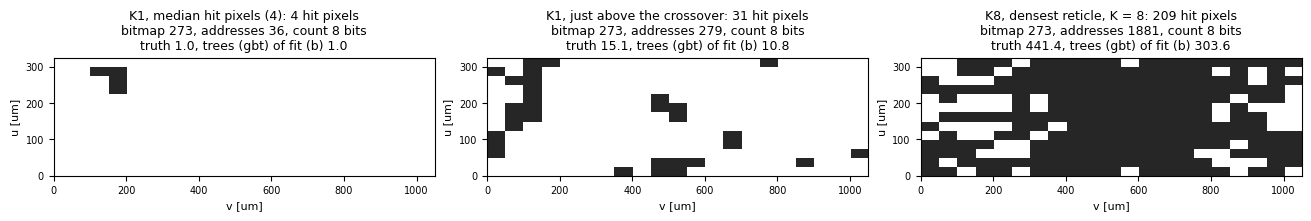

K1, median hit pixels (4): layer 10, 4 of 273 pixels hit in 1 cluster, truth 1.0, gbt (b) 1.0
K1, just above the crossover: layer 17, 31 of 273 pixels hit in 8 clusters, truth 15.1, gbt (b) 10.8
K8, densest reticle, K = 8: layer 7, 209 of 273 pixels hit in 1 cluster, truth 441.4, gbt (b) 303.6


In [31]:
def hit_map(D, i):
    # the hit map of reticle i, rebuilt from the hit pixels of mc.prepare
    p = D['pix']
    a, b = np.searchsorted(p['ret'], [i, i + 1])
    h = np.zeros((NY, NX), bool)
    h[p['iy'][a:b], p['ix'][a:b]] = True
    return h


PX, PY = D1['pitch_x'], D1['pitch_y']
m1 = D1['n_hits'] > 0
typical = int(np.median(D1['n_hits'][m1]))
cand = np.flatnonzero(D1['n_hits'] == typical)
i_typ = int(cand[np.argmin(np.abs(D1['n_frac'][cand] - 1))])
i_cross = int(np.flatnonzero(D1['n_hits'] == CROSS + 1)[0])
i_dense = int(np.argmax(DS['K8']['n_frac']))
SHOWN = (('K1', i_typ, f'median hit pixels ({typical})'), ('K1', i_cross, 'just above the crossover'),
         ('K8', i_dense, 'densest reticle, K = 8'))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3), constrained_layout=True)
for ax, (t, i, why) in zip(axs, SHOWN):
    D = DS[t]
    h = int(D['n_hits'][i])
    ax.imshow(hit_map(D, i), origin='lower', interpolation='nearest', extent=(0, NX * PX, 0, NY * PY),
              cmap=plt.matplotlib.colors.ListedColormap(['white', '0.15']), vmin=0, vmax=1)
    ax.set_title(f"{t}, {why}: {h} hit pixels\nbitmap {S_PIX}, addresses {A_BITS * h}, count {C_BITS} bits\n"
                 f"truth {D['n_frac'][i]:.1f}, trees (gbt) of fit (b) {FIT['b'][t]['gbt'][i]:.1f}", fontsize=9)
    ax.set_xlabel('v [um]', fontsize=8)
    ax.set_ylabel('u [um]', fontsize=8)
    ax.tick_params(labelsize=7)
plt.show()
for t, i, why in SHOWN:
    D = DS[t]
    n_cl = int(D['n_clusters'][i])
    print(f"{t}, {why}: layer {D['layer'][i]}, {D['n_hits'][i]} of {S_PIX} pixels hit in {n_cl} "
          f"cluster{'' if n_cl == 1 else 's'}, truth {D['n_frac'][i]:.1f}, gbt (b) {FIT['b'][t]['gbt'][i]:.1f}")

- Single showers: 273, 51 and 8 bits per reticle with a hit, and 781, 147 and 22.9 kbit per
  shower, the write-up's column for 21 x 13 reticles. The count is 6.41 times smaller than the
  address list and 34.12 times smaller than the bitmap.
- The address list outgrows the bitmap above 30 hit pixels. That is 0.82% of the reticles with a
  hit at K = 1, holding 15.1% of the crossings, and 4.45% at K = 8, holding 48.6%. At K = 8 the
  address list is 9.90 times the counts.
- The range: clipping the count at 63.75 loses 0.09% of the crossings at K = 1. At K = 8, 19.73%
  of the crossings sit in reticles above 63.75, and clipping loses 11.64%. The densest reticle
  holds 441.4 crossings; in steps of 1 it needs 9 bits.
- The densest reticle (right) has 209 of its 273 pixels hit, all in one cluster, and `gbt` (b)
  gives it 303.6.

The write-up also gives the volumes for reticles of 42 x 26 pixels. That needs a reticle file cut
at that size, which is not part of this sample, so we leave it out.

The write-up goes further than this notebook: small networks trained on the hit maps (its sections
6.1 to 6.4), the threshold and the noise (6.5), the size of the reticle (6.6) and the limits of the study (8). Its section 9 gives the commands
that make every number again.

**The write-up's section 7 asks the last question: what would the edge logic at each sensor have to
compute to send these counts?**

## 8. Summary

The points below are printed from the numbers measured in this notebook.

In [32]:
r_t, r_h, r_c = ROW['true crossings'], ROW['hit pixels'], ROW['charge']
print(f"1. Data: {D1['n']:,} reticles of {N_SHOWERS} single showers of {GUN}; every reticle estimated by tables and "
      f"models fitted on the other four blocks of {BLOCK} showers.")
print(f"2. Layers 0 to 4 (estimate / truth): " + ', '.join(f"{nm} {GROUP1[nm][0]:.2f}" for nm in NAMES)
      + f"; layers 20 to 29: " + ', '.join(f"{nm} {GROUP1[nm][-1]:.2f}" for nm in NAMES) + ".")
print(f"3. Spread of the weighted shower total: truth {100 * r_t['spread_w']:.1f}%, hit pixels {100 * r_h['spread_w']:.1f}%, "
      f"charge {100 * r_c['spread_w']:.1f}%; " + ', '.join(f"{nm} {100 * ROW[nm]['spread_w']:.1f}%" for nm in NAMES)
      + f". Unweighted: truth {100 * r_t['spread_u']:.1f}%.")
print(f"4. Ratio of the weighted totals, mean +- spread over the showers: "
      + ', '.join(f"{nm} {ROW[nm]['ratio_w']:.3f} +- {ROW[nm]['ratio_sd_w']:.3f}" for nm in NAMES) + ".")
print(f"5. Differences of weighted spreads (bootstrap): " + ', '.join(f"{a_} minus {b_} {d0:.2f} +- {sd:.2f}"
                                                                    for (a_, b_), (d0, sd) in BOOT.items()) + " points.")
print(f"6. gbt rounded to 8 bits in steps of 0.25: weighted spread {100 * spread(TOT['gbt', True]):.2f}% -> "
      f"{100 * R025[0]:.2f}%; in steps of 1: {100 * R1_[0]:.2f}% and the total {100 * (R1_[2] - 1):+.1f}%.")
print(f"7. Density, ratio of the weighted totals at K = 8: trained on K = 1: " +
      ', '.join(f"{nm} {RATIO_K['a'][nm]['K8']:.3f}" for nm in NAMES) + "; on the mix: " +
      ', '.join(f"{nm} {RATIO_K['b'][nm]['K8']:.3f}" for nm in NAMES) + "; on K = 1 and 2: " +
      ', '.join(f"{nm} {RATIO_K['c'][nm]['K8']:.3f}" for nm in NAMES) + ".")
print(f"8. Trained on the mix, at K = 1: " + ', '.join(f"{nm} {RATIO_K['b'][nm]['K1']:.3f}" for nm in NAMES)
      + f"; layers 0 to 4 on single showers: " + ', '.join(f"{nm} {GROUP_MIX[nm][0]:.2f}" for nm in NAMES) + ".")
mine, mine_sh, n_ = VOL['K1']
print(f"9. Data volume, single showers: {mine['bitmap']:.0f} / {mine['zero_suppressed']:.0f} / {mine['count']:.0f} bits per "
      f"reticle with a hit (bitmap / addresses / count), {n_:,.0f} such reticles and {mine_sh['bitmap'] / 1e3:.0f} / "
      f"{mine_sh['zero_suppressed'] / 1e3:.0f} / {mine_sh['count'] / 1e3:.1f} kbit per shower; at K = 8 the addresses are "
      f"{ZS_OVER['K8']:.1f} times the counts, and a count clipped at {TOP} loses {RANGE['K8'][1]:.0%} of the total.")

1. Data: 600,628 reticles of 200 single showers of 50 GeV gamma; every reticle estimated by tables and models fitted on the other four blocks of 40 showers.
2. Layers 0 to 4 (estimate / truth): hits 0.72, clusters 0.72, cluster_shape 0.75, gbt 0.89, gbt_layer 0.99, analog 0.93; layers 20 to 29: hits 1.12, clusters 1.01, cluster_shape 1.12, gbt 1.00, gbt_layer 1.00, analog 1.12.
3. Spread of the weighted shower total: truth 2.2%, hit pixels 3.8%, charge 3.4%; hits 3.9%, clusters 2.8%, cluster_shape 3.0%, gbt 2.6%, gbt_layer 2.9%, analog 3.3%. Unweighted: truth 7.0%.
4. Ratio of the weighted totals, mean +- spread over the showers: hits 1.012 +- 0.027, clusters 1.000 +- 0.017, cluster_shape 1.011 +- 0.016, gbt 0.999 +- 0.011, gbt_layer 0.998 +- 0.013, analog 1.012 +- 0.022.
5. Differences of weighted spreads (bootstrap): gbt minus true crossings 0.44 +- 0.07, hit pixels minus gbt 1.21 +- 0.16, charge minus gbt 0.81 +- 0.14, clusters minus gbt 0.22 +- 0.10, gbt_layer minus gbt 0.32 +- 0.0

## Appendix A. Checks against the study code and the write-up

The main line shows each step; this appendix checks it against the code of the study and against
the numbers of the write-up, in the order of the sections. The checks run every time. With
`CHECK_NUMBERS = True` (the configuration cell) a check that fails stops the notebook; with `False`
it prints "check skipped:" and what differs.

The rule for every comparison with the write-up: tables and numbers that need no fit are checked to
the write-up's printed digits; the trees are printed beside the write-up's number, with the
tolerance we expect, and never checked (notebook 11 found them a little off and left the difference
untraced). The write-up's numbers below were read from it when this notebook was built.

**A.1 Section 2: the write-up's table 6.1, and the rms of each block.** For `hits`, `clusters`,
`cluster_shape` and `gbt` the estimates of section 2 must give the write-up's table 6.1 (the rms
per bin of the true count, over all 200 showers): the tables to its printed digits; the trees beside
it, with, for scale, the statistical error of an rms from the N reticles of its bin, about
1 / sqrt(2N). Both fits use the same reticles, so their gap is no sampling error.

The second part repeats notebook 11's comparison with the same estimates. Comparing one block of 40
showers with all 200 would need a tolerance that we cannot set in advance: the rms of a dense bin is
set by a few reticles with large errors. So each block is scored on its own, and the rows "block
min" and "block max" show how much one block can differ from another; "range / rms" gives their
difference as a fraction of the 5-block rms. The test block is the last one, notebook 11's test
showers.

In [33]:
WRITEUP.update({
    'section_6_1': {'bins': ['1', '2', '3', '4-5', '6-8', '9-12', '13-20', '21-40', '41-80'],
                    'reticles': [342325, 54697, 18765, 14931, 7273, 3099, 2592, 1881, 912],
                    'rms': {'hits': [0.57, 1.1, 1.81, 2.79, 4.18, 5.72, 7.43, 10.99, 13.01],
                            'clusters': [0.32, 0.67, 1.0, 1.62, 3.44, 6.13, 7.11, 12.0, 34.87],
                            'cluster_shape': [0.52, 0.84, 1.06, 1.36, 2.18, 3.76, 7.28, 15.48, 20.62],
                            'analog': [0.62, 1.05, 2.56, 2.35, 3.47, 6.13, 4.31, 4.09, 4.87],
                            'gbt': [0.28, 0.59, 0.88, 1.2, 1.89, 2.98, 4.37, 6.52, 8.03]},
                    'gbt_layer_13_20': 4.2},                      # in the text of section 6.2
})

W61 = WRITEUP['section_6_1']
B61 = {nm: {r['bin']: r for r in mc.binned(P1[nm], D1['n_frac'])} for nm in NAMES}
n_all = [B61['hits'][b]['N'] for b in W61['bins']]
check(n_all == W61['reticles'], f"reticles per bin {n_all} differ from the write-up's {W61['reticles']}")
print(f"check: the reticles per bin are those of the write-up ({', '.join(f'{x:,}' for x in n_all)})")
print("\nrms per bin       " + ''.join(f"{b:>8s}" for b in W61['bins']))
for nm in W61['rms']:
    print(f"{nm:18s}" + ''.join(f"{B61[nm][b]['rms']:8.3f}" for b in W61['bins']))
    print(f"{'  write-up':18s}" + ''.join(f"{x:8.2f}" for x in W61['rms'][nm]))
for nm in TABLES:
    d_ = max(abs(B61[nm][b]['rms'] - x) for b, x in zip(W61['bins'], W61['rms'][nm]))
    check(all(digits_match(B61[nm][b]['rms'], x, 2) for b, x in zip(W61['bins'], W61['rms'][nm])),
          f"{nm}: the rms differs from the write-up's table 6.1 by up to {d_:.4f}")
    print(f"check: {nm}: the rms equals the write-up's to its printed digits (largest difference {d_:.4f})")
rel = {b: abs(B61['gbt'][b]['rms'] - x) / x for b, x in zip(W61['bins'], W61['rms']['gbt'])}
b_g = max(rel, key=rel.get)
print(f"gbt: largest difference {rel[b_g]:.1%}, in the bin {b_g} ({B61['gbt'][b_g]['N']:,} reticles; 1 / sqrt(2N) = "
      f"{1 / np.sqrt(2 * B61['gbt'][b_g]['N']):.1%}); printed, not asserted")
r_gl = B61['gbt_layer']['13-20']
print(f"gbt_layer at 13 to 20 crossings: rms {r_gl['rms']:.3f} against the write-up's {W61['gbt_layer_13_20']} "
      f"({abs(r_gl['rms'] - W61['gbt_layer_13_20']) / W61['gbt_layer_13_20']:.1%} apart; 1 / sqrt(2N) = "
      f"{1 / np.sqrt(2 * r_gl['N']):.1%}); printed, not asserted")

check: the reticles per bin are those of the write-up (342,325, 54,697, 18,765, 14,931, 7,273, 3,099, 2,592, 1,881, 912)

rms per bin              1       2       3     4-5     6-8    9-12   13-20   21-40   41-80
hits                 0.574   1.105   1.812   2.791   4.180   5.717   7.435  10.990  13.010
  write-up            0.57    1.10    1.81    2.79    4.18    5.72    7.43   10.99   13.01
clusters             0.317   0.669   1.000   1.615   3.438   6.132   7.108  11.996  34.869
  write-up            0.32    0.67    1.00    1.62    3.44    6.13    7.11   12.00   34.87
cluster_shape        0.523   0.844   1.065   1.358   2.179   3.764   7.281  15.481  20.624
  write-up            0.52    0.84    1.06    1.36    2.18    3.76    7.28   15.48   20.62
analog               0.622   1.049   2.561   2.353   3.469   6.134   4.313   4.092   4.868
  write-up            0.62    1.05    2.56    2.35    3.47    6.13    4.31    4.09    4.87
gbt                  0.277   0.593   0.879   1.198   1.891 

In [34]:
NAMES_61 = ('hits', 'clusters', 'cluster_shape', 'gbt')
PB = P1                                         # the five-block estimates of section 2
for f in range(N_BLOCKS):
    tr_f, ev_f = D1['fold'] != f, D1['fold'] == f
    mc.check_unseen(N_SHOWERS, [D1], [tr_f], [D1], [ev_f], f'block {f}')
print(f"check: in each of the {N_BLOCKS} blocks no shower is both trained on and estimated")
ALL5 = {nm: {r['bin']: r for r in mc.binned(PB[nm], D1['n_frac'])} for nm in NAMES_61}
BLOCK_RMS = {nm: [{r['bin']: r for r in mc.binned(PB[nm][D1['fold'] == f], D1['n_frac'][D1['fold'] == f])}
              for f in range(N_BLOCKS)] for nm in NAMES_61}
n_all = [ALL5['hits'][b]['N'] for b in W61['bins']]
check(n_all == W61['reticles'], f"reticles per bin {n_all} differ from the write-up's {W61['reticles']}")
print(f"check: the reticles per bin over all 200 showers are those of the write-up ({', '.join(f'{x:,}' for x in n_all)})")

print("\nrms per bin    " + ''.join(f"{b:>8s}" for b in W61['bins']))
TOL = {}
for nm in NAMES_61:
    mine = np.array([ALL5[nm][b]['rms'] for b in W61['bins']])
    doc = np.array(W61['rms'][nm])
    blk = np.array([[BLOCK_RMS[nm][f][b]['rms'] for b in W61['bins']] for f in range(N_BLOCKS)])
    print(f"{nm}")
    print("  test block   " + ''.join(f"{x:8.2f}" for x in blk[-1]))
    print("  block min    " + ''.join(f"{x:8.2f}" for x in blk.min(0)))
    print("  block max    " + ''.join(f"{x:8.2f}" for x in blk.max(0)))
    print("  range / rms  " + ''.join(f"{x:8.2f}" for x in (blk.max(0) - blk.min(0)) / mine))
    print("  all 5 blocks " + ''.join(f"{x:8.2f}" for x in mine))
    print("  write-up     " + ''.join(f"{x:8.2f}" for x in doc))
    TOL[nm] = np.abs(mine - doc) / doc
for nm in ('hits', 'clusters', 'cluster_shape'):
    d_ = np.abs(np.array([ALL5[nm][b]['rms'] for b in W61['bins']]) - W61['rms'][nm]).max()
    check(d_ <= 0.006, f"{nm}: the 5-block rms differs from the write-up by up to {d_:.3f}")
    print(f"check: {nm}: the 5-block rms equals the write-up to its printed digits (largest difference {d_:.3f})")
b_g = W61['bins'][int(np.argmax(TOL['gbt']))]       # the bin of the largest difference
n_g = ALL5['gbt'][b_g]['N']
print(f"gbt: the 5-block rms differs from the write-up by up to {TOL['gbt'].max():.1%}, in the bin {b_g}; printed, "
      f"not asserted ({n_g:,} reticles in that bin over the five blocks; the statistical error of an rms from N "
      f"values is about 1/sqrt(2N) = {1 / np.sqrt(2 * n_g):.1%})")

check: in each of the 5 blocks no shower is both trained on and estimated


check: the reticles per bin over all 200 showers are those of the write-up (342,325, 54,697, 18,765, 14,931, 7,273, 3,099, 2,592, 1,881, 912)

rms per bin           1       2       3     4-5     6-8    9-12   13-20   21-40   41-80
hits
  test block       0.59    1.12    1.98    2.70    4.18    5.87    7.42   11.06   13.72
  block min        0.55    1.06    1.70    2.70    4.07    5.56    7.20   10.43   12.07
  block max        0.59    1.13    1.98    2.90    4.24    5.87    7.67   11.23   13.75
  range / rms      0.06    0.07    0.15    0.07    0.04    0.05    0.06    0.07    0.13
  all 5 blocks     0.57    1.10    1.81    2.79    4.18    5.72    7.43   10.99   13.01
  write-up         0.57    1.10    1.81    2.79    4.18    5.72    7.43   10.99   13.01
clusters
  test block       0.32    0.67    1.01    1.68    3.55    6.28    6.84   12.15   35.43
  block min        0.31    0.66    0.98    1.52    3.27    5.95    6.81   11.64   33.69
  block max        0.32    0.68    1.02    1.68    

**A.2 Section 3: the groups of layers.** The two rows without a fit (the share of the crossings and
the hit pixels per crossing) and the ratios of the tables must give the write-up's printed digits.
The write-up gives the ratios with two digits, rounded once from the measured values; we require ours
to round to the same two digits. Two entries lie within a thousandth of the half digit (printed
below): `hits` in layers 5 to 9 and `gbt` in layers 20 to 29, 0.9447 and 1.0048, round to 0.94 and
1.00, the write-up's entries; rounding them to three digits first would give 0.95 and 1.01, a double
rounding the write-up avoids.

In [35]:
check(all(digits_match(100 * x, d_, 1) for x, d_ in zip(SHARE_G, W64['share'])) and
      all(digits_match(x, d_, 1) for x, d_ in zip(HPC_G, W64['hits_per_crossing'])),
      "the shares or the hit pixels per crossing differ from the write-up")
print("check: the shares and the hit pixels per crossing equal the write-up's to its printed digits")
for nm in ('hits', 'clusters'):
    check(all(digits_match(x, y, 2) for x, y in zip(GROUP1[nm], W64['ratio'][nm])),
          f"{nm}: a layer-group ratio differs from the write-up by {np.abs(GROUP1[nm] - W64['ratio'][nm]).max():.4f}")
    print(f"check: {nm}: the five ratios round to the write-up's two digits")
for nm in TREES:
    same = [digits_match(x, y, 2) for x, y in zip(GROUP1[nm], W64['ratio'][nm])]
    print(f"{nm}: {sum(same)} of the {nG} ratios round to the write-up's two digits; largest difference "
          f"{np.abs(GROUP1[nm] - W64['ratio'][nm]).max():.4f}; printed, not asserted")
for nm in W64['ratio']:
    for (a_, b_), x, y in zip(GROUPS, GROUP1[nm], W64['ratio'][nm]):
        if abs(x - y) > 0.004:
            print(f"close to the half digit: {nm}, layers {a_} to {b_}: {x:.4f}, which rounds to {x:.2f} "
                  f"({x:.3f} to three digits); the write-up shows {y:.2f}")

check: the shares and the hit pixels per crossing equal the write-up's to its printed digits
check: hits: the five ratios round to the write-up's two digits
check: clusters: the five ratios round to the write-up's two digits
gbt: 5 of the 5 ratios round to the write-up's two digits; largest difference 0.0048; printed, not asserted
gbt_layer: 5 of the 5 ratios round to the write-up's two digits; largest difference 0.0040; printed, not asserted
close to the half digit: hits, layers 5 to 9: 0.9447, which rounds to 0.94 (0.945 to three digits); the write-up shows 0.94
close to the half digit: hits, layers 10 to 14: 1.0045, which rounds to 1.00 (1.004 to three digits); the write-up shows 1.00
close to the half digit: clusters, layers 10 to 14: 1.0340, which rounds to 1.03 (1.034 to three digits); the write-up shows 1.03
close to the half digit: gbt, layers 20 to 29: 1.0048, which rounds to 1.00 (1.005 to three digits); the write-up shows 1.00
close to the half digit: gbt_layer, layers 20 to

Notebook 11 gave the same ratios for its 40 test showers (the last block), with their standard
deviation over resamplings of the 40 showers (a bootstrap), beside the five-block ratios of all 200
showers and the write-up's. The cell below prints that table again from the estimates of section 2:
the test showers carry the estimates of the models fitted on the other four blocks, notebook 11's
models.

In [36]:
NAMES_11 = ('hits', 'clusters', 'cluster_shape', 'gbt', 'gbt_layer')    # the estimators of notebook 11
N_TRAIN = (N_BLOCKS - 1) * BLOCK                # notebook 11's split: showers 0 to 159 train, 160 to 199 test
TEST = D1['fold'] == N_BLOCKS - 1
check(np.array_equal(TEST, D1['super_evt'] >= N_TRAIN), "the last block is not showers 160 to 199")
P = {nm: P1[nm][TEST] for nm in NAMES_11}
TRUTH_T, lay_t = D1['n_frac'][TEST], D1['layer'][TEST]
sh_t, n_test = D1['super_evt'][TEST] - N_TRAIN, N_SHOWERS - N_TRAIN
G = GROUPS
share = np.bincount(g_all, D1['n_frac'], nG) / D1['n_frac'].sum()
hpc = np.bincount(g_all, D1['n_hits'], nG) / np.bincount(g_all, D1['n_frac'], nG)
check(np.allclose(100 * share, W64['share'], atol=0.05 + 1e-9) and np.allclose(hpc, W64['hits_per_crossing'], atol=0.05 + 1e-9),
      "the shares or hit pixels per crossing differ from the write-up")
print("layers                 " + ''.join(f"{f'{a} to {b}':>16s}" for a, b in G))
print("share of the crossings " + ''.join(f"{x:16.1%}" for x in share))
print("hit pixels per crossing" + ''.join(f"{x:16.2f}" for x in hpc))
print("check: both rows equal the write-up's to its printed digits (all 200 showers)")

g_t = grp[lay_t]
boot_t = np.random.default_rng(SEED + 4).multinomial(n_test, np.full(n_test, 1 / n_test), size=2000)
t_sg = np.bincount(sh_t * nG + g_t, TRUTH_T, n_test * nG).reshape(n_test, nG)
GROUP_RATIO, DEV5 = {}, {}
print("\nestimate / truth, test showers (+- bootstrap standard deviation), all 200 showers in 5 blocks, and the write-up")
for nm in NAMES_11:
    e_sg = np.bincount(sh_t * nG + g_t, P[nm], n_test * nG).reshape(n_test, nG)
    r = e_sg.sum(0) / t_sg.sum(0)
    sig = ((boot_t @ e_sg) / (boot_t @ t_sg)).std(0)
    GROUP_RATIO[nm] = r
    line = ''.join(f"{x:10.3f} +-{s:.3f}" for x, s in zip(r, sig))
    print(f"{nm:14s}{line}")
    if nm in W64['ratio']:
        doc = np.array(W64['ratio'][nm])
        r5 = np.bincount(g_all, PB[nm], nG) / np.bincount(g_all, D1['n_frac'], nG)
        print(f"{'  5 blocks':14s}" + ''.join(f"{x:16.3f}" for x in r5))
        print(f"{'  write-up':14s}" + ''.join(f"{x:16.2f}" for x in doc))
        DEV5[nm] = np.abs(r5 - doc).max()
for nm in ('hits', 'clusters'):
    check(DEV5[nm] <= 0.006, f"{nm}: a five-block layer-group ratio differs from the write-up by {DEV5[nm]:.3f}")
    print(f"check: {nm}: the five-block ratios equal the write-up's to its printed digits (largest difference "
          f"{DEV5[nm]:.3f})")
for nm in ('gbt', 'gbt_layer'):
    print(f"{nm}: the five-block ratios differ from the write-up's by up to {DEV5[nm]:.3f}; printed, not asserted")

layers                           0 to 4          5 to 9        10 to 14        15 to 19        20 to 29
share of the crossings             3.1%           21.4%           35.5%           27.9%           12.0%
hit pixels per crossing            2.91            3.49            4.02            4.35            4.70
check: both rows equal the write-up's to its printed digits (all 200 showers)

estimate / truth, test showers (+- bootstrap standard deviation), all 200 showers in 5 blocks, and the write-up
hits               0.721 +-0.020     0.949 +-0.013     1.010 +-0.008     1.010 +-0.007     1.128 +-0.013
  5 blocks               0.723           0.945           1.004           1.008           1.123
  write-up                0.72            0.94            1.00            1.01            1.12
clusters           0.707 +-0.018     0.910 +-0.010     1.035 +-0.007     1.033 +-0.004     1.018 +-0.006
  5 blocks               0.718           0.919           1.034           1.038           1.014
  

**A.3 Section 4: the shower totals.** The totals made by hand against `mc.event_totals` and
`mc.event_references`, the spreads and ratios of the table of section 4 against the write-up's
table 6.2, and the share of the crossings in reticles without a hit pixel against the write-up's.

In [37]:
ref = mc.event_references(D1)
pairs = [(ROW['hit pixels']['spread_w'], ref['weighted']['spread_hits']), (ROW['hit pixels']['spread_u'], ref['spread_hits']),
         (ROW['charge']['spread_w'], ref['weighted']['spread_charge']), (ROW['charge']['spread_u'], ref['spread_charge'])]
for nm in NAMES:
    e = mc.event_totals(D1, P1[nm], D1['n_frac'])
    for sub, key in ((e['weighted'], 'w'), (e, 'u')):
        pairs += [(ROW[nm][f'spread_{key}'], sub['spread_est']), (ROW['true crossings'][f'spread_{key}'], sub['spread_truth']),
                  (ROW[nm][f'ratio_{key}'], sub['ratio_mean']), (ROW[nm][f'ratio_sd_{key}'], sub['ratio_std'])]
dmax = max(abs(a_ - b_) / abs(b_) for a_, b_ in pairs)
check(dmax < 1e-12, f"the totals by hand differ from mc.event_totals / mc.event_references by {dmax:.1e} (relative)")
print(f"check: the {len(pairs)} spreads and ratios made by hand equal those of mc.event_totals and mc.event_references "
      f"(largest relative difference {dmax:.1e})")

check: the 52 spreads and ratios made by hand equal those of mc.event_totals and mc.event_references (largest relative difference 0.0e+00)


In [38]:
def check_row(k, ratio):
    r_, doc = ROW[k], W62[k]
    ok = digits_match(100 * r_['spread_w'], doc[0], 1) and digits_match(100 * r_['spread_u'], doc[1], 1)
    if ratio:
        ok = ok and digits_match(r_['ratio_w'], doc[2], 3) and digits_match(r_['ratio_sd_w'], doc[3], 3)
    return ok


for k in ('true crossings', 'hit pixels', 'charge'):
    check(check_row(k, False), f"{k}: the spreads {100 * ROW[k]['spread_w']:.1f}% (weighted) and "
                               f"{100 * ROW[k]['spread_u']:.1f}% (unweighted) are not the write-up's {W62[k][0]}% and {W62[k][1]}%")
    print(f"check: {k}: both spreads equal the write-up's to its printed digits")
for nm in TABLES:
    check(check_row(nm, True), f"{nm}: a spread or the ratio differs from the write-up's table 6.2")
    print(f"check: {nm}: both spreads and the ratio (mean and spread) equal the write-up's to its printed digits")
g_, doc = ROW['gbt'], W62['gbt']
within = (abs(100 * g_['spread_w'] - doc[0]) <= 0.3 and abs(100 * g_['spread_u'] - doc[1]) <= 0.3
          and abs(g_['ratio_w'] - doc[2]) <= 0.01 and abs(g_['ratio_sd_w'] - doc[3]) <= 0.01)
print(f"gbt: spreads {100 * g_['spread_w']:.2f}% and {100 * g_['spread_u']:.2f}%, ratio {g_['ratio_w']:.4f} +- "
      f"{g_['ratio_sd_w']:.4f}; within 0.3 points and 0.01 of the write-up's: {within}; printed, not asserted")
gl_ = ROW['gbt_layer']
print(f"gbt_layer: weighted spread {100 * gl_['spread_w']:.2f}% against the write-up's {W62['gbt_layer'][0]}% "
      f"(within 0.3 points: {abs(100 * gl_['spread_w'] - W62['gbt_layer'][0]) <= 0.3}); printed, not asserted")
check(digits_match(100 * MISSING, W62['missing'], 1),
      f"{MISSING:.3%} of the crossings in reticles without a hit pixel, not the write-up's {W62['missing']}%")
print(f"check: {MISSING:.2%} rounds to the write-up's {W62['missing']}%")

check: true crossings: both spreads equal the write-up's to its printed digits
check: hit pixels: both spreads equal the write-up's to its printed digits
check: charge: both spreads equal the write-up's to its printed digits
check: hits: both spreads and the ratio (mean and spread) equal the write-up's to its printed digits
check: clusters: both spreads and the ratio (mean and spread) equal the write-up's to its printed digits
check: cluster_shape: both spreads and the ratio (mean and spread) equal the write-up's to its printed digits
check: analog: both spreads and the ratio (mean and spread) equal the write-up's to its printed digits
gbt: spreads 2.60% and 7.31%, ratio 0.9991 +- 0.0109; within 0.3 points and 0.01 of the write-up's: True; printed, not asserted
gbt_layer: weighted spread 2.92% against the write-up's 2.9% (within 0.3 points: True); printed, not asserted
check: 0.17% rounds to the write-up's 0.2%


**A.4 Section 5: fits (b) and (c) and the spread per K against the write-up.** Fit (b) must give
the first table of the write-up's section 6.4 and fit (c) the second: the tables to the printed
three digits; `gbt` printed with the 0.01 we expect, and `gbt_layer` beside the two numbers the
write-up quotes in its text. Then the spread of the true weighted total at each K against the
write-up's.

In [39]:
WRITEUP.update({
    # 6.4: ratio of the weighted totals at K = 1, 2, 4, 8, trained on the mix of all four
    'section_6_4_mix': {'hits': [0.920, 0.946, 1.015, 1.138], 'clusters': [1.063, 1.050, 1.003, 0.917],
                        'cluster_shape': [0.982, 0.983, 1.002, 1.068], 'analog': [0.970, 0.982, 1.012, 1.059],
                        'gbt': [0.969, 0.984, 1.003, 1.041], 'gbt_layer_K1_K8': (0.967, 1.042)},
    # 6.4: the same at K = 4, 8, trained on K = 1 and 2
    'section_6_4_extrap': {'hits': [1.140, 1.274], 'clusters': [0.949, 0.866], 'cluster_shape': [1.045, 1.106],
                           'analog': [1.056, 1.112], 'gbt': [1.024, 1.044]},
})
W_MIX, W_EXT = WRITEUP['section_6_4_mix'], WRITEUP['section_6_4_extrap']
for f, doc, tags_ in (('b', W_MIX, list(TAGS)), ('c', W_EXT, ['K4', 'K8'])):
    print(f"{FIT_TITLE[f]}, here / write-up:")
    for nm in ('hits', 'clusters', 'cluster_shape', 'analog', 'gbt'):
        print(f"  {nm:16s}" + ''.join(f"{RATIO_K[f][nm][t]:9.4f} /{d_:6.3f}" for t, d_ in zip(tags_, doc[nm])))
    for nm in TABLES:
        d_ = max(abs(RATIO_K[f][nm][t] - x) for t, x in zip(tags_, doc[nm]))
        check(all(digits_match(RATIO_K[f][nm][t], x, 3) for t, x in zip(tags_, doc[nm])),
              f"fit ({f}), {nm}: a ratio differs from the write-up by {d_:.4f}")
        print(f"  check: {nm}: equal to the write-up's to its printed digits (largest difference {d_:.4f})")
    d_ = max(abs(RATIO_K[f]['gbt'][t] - x) for t, x in zip(tags_, doc['gbt']))
    print(f"  gbt: largest difference {d_:.4f}, within 0.01: {d_ <= 0.01}; printed, not asserted")
gl1, gl8 = WRITEUP['section_6_4_mix']['gbt_layer_K1_K8']
print(f"gbt_layer, fit (b): {RATIO_K['b']['gbt_layer']['K1']:.4f} at K = 1 and {RATIO_K['b']['gbt_layer']['K8']:.4f} at "
      f"K = 8, the write-up's text {gl1} and {gl8}; printed, not asserted")
check(all(digits_match(100 * SPREAD_K[t][0], doc, 1) for t, doc in zip(TAGS, WRITEUP['spread_truth_per_K'])),
      "the spread of the true weighted totals per K differs from the write-up's")
print("check: the spreads of the true weighted totals equal the write-up's to its printed digits")

(b) trained on K = 1, 2, 4, 8, here / write-up:
  hits               0.9201 / 0.920   0.9458 / 0.946   1.0152 / 1.015   1.1381 / 1.138
  clusters           1.0628 / 1.063   1.0496 / 1.050   1.0027 / 1.003   0.9174 / 0.917
  cluster_shape      0.9821 / 0.982   0.9830 / 0.983   1.0024 / 1.002   1.0682 / 1.068
  analog             0.9701 / 0.970   0.9820 / 0.982   1.0117 / 1.012   1.0590 / 1.059
  gbt                0.9688 / 0.969   0.9837 / 0.984   1.0021 / 1.003   1.0397 / 1.041
  check: hits: equal to the write-up's to its printed digits (largest difference 0.0002)
  check: clusters: equal to the write-up's to its printed digits (largest difference 0.0004)
  check: cluster_shape: equal to the write-up's to its printed digits (largest difference 0.0004)
  check: analog: equal to the write-up's to its printed digits (largest difference 0.0003)
  gbt: largest difference 0.0013, within 0.01: True; printed, not asserted
(c) trained on K = 1, 2, here / write-up:
  hits               1.1401 /

**A.5 Section 7: the data volume.** The bits per reticle and per stack made by hand against
`mc.data_volume` and its crossover; then, against the write-up's section 6.7, the single-shower
volumes, the gains of the count, the zero-suppressed volume at K = 8 and the range of the count.

In [40]:
for t, D in DS.items():
    v = mc.data_volume(D)
    mine, mine_sh, _ = VOL[t]
    check(v['address_bits'] == A_BITS and v['bitmap_bits'] == S_PIX and
          all(np.isclose(mine[k], v['mean_bits_per_reticle'][k], rtol=1e-12) and
              np.isclose(mine_sh[k], v['bits_per_shower'][k], rtol=1e-12) for k in mine), f"{t}: mc.data_volume differs")
print("check: the bits per reticle and per stack made by hand equal mc.data_volume's in all four files")
check(A_BITS * CROSS <= S_PIX < A_BITS * (CROSS + 1) and mc.data_volume(D1)['crossover_hits'] == CROSS + 1,
      "the bit count and mc.data_volume's crossover disagree")
print(f"check: {A_BITS} x {CROSS} = {A_BITS * CROSS} bits fit in the bitmap of {S_PIX}, {A_BITS} x {CROSS + 1} = "
      f"{A_BITS * (CROSS + 1)} do not (mc.data_volume: crossover at {CROSS + 1} hit pixels)")
mine, mine_sh, _ = VOL['K1']
got = (mine['bitmap'], mine['zero_suppressed'], mine['count'], mine_sh['bitmap'] / 1e3, mine_sh['zero_suppressed'] / 1e3,
       mine_sh['count'] / 1e3)
doc = W67['bits'] + W67['kbit']
check(all(digits_match(x, d_, nd) for x, d_, nd in zip(got, doc, (0, 0, 0, 0, 0, 1))),
      f"the single-shower volumes {got} differ from the write-up's {doc}")
print(f"check: single showers: {got[0]:.0f} / {got[1]:.0f} / {got[2]:.0f} bits per reticle and {got[3]:.0f} / {got[4]:.0f} / "
      f"{got[5]:.1f} kbit per shower, the write-up's 21 x 13 column to its printed digits")
check(digits_match(smaller[0], W67['count_smaller'][0], 0) and digits_match(smaller[1], W67['count_smaller'][1], 0)
      and digits_match(smaller_ad[0], W67['with_address'][1], 1) and digits_match(smaller_ad[1], W67['with_address'][2], 0),
      "the gain of the count differs from the write-up's")
print("check: the four ratios equal the write-up's to its printed digits")
check(digits_match(ZS_OVER['K8'], W67['zs_over_count_K8'], 0),
      f"at K = 8 the addresses are {ZS_OVER['K8']:.2f} times the counts, not the write-up's {W67['zs_over_count_K8']}")
print(f"check: at K = 8 the zero-suppressed volume is {ZS_OVER['K8']:.2f} times that of the counts, the write-up's "
      f"{W67['zs_over_count_K8']} to its printed digits")
got = (100 * RANGE['K1'][1], 100 * RANGE['K8'][0], 100 * RANGE['K8'][1], RANGE['K8'][2])
doc = (W67['clip_loss']['K1'], W67['above_range_K8'], W67['clip_loss']['K8'], W67['densest_K8'])
check(all(digits_match(x, d_, nd) for x, d_, nd in zip(got, doc, (1, 0, 0, 0))),
      f"the range numbers {got} differ from the write-up's {doc}")
print(f"check: clipping loses {got[0]:.1f}% at K = 1; at K = 8, {got[1]:.0f}% of the crossings sit above {TOP}, clipping "
      f"loses {got[2]:.0f}% and the densest reticle holds {got[3]:.0f}: the write-up's numbers to its printed digits")
print("\nfive-block refits: " + '; '.join(f"{k} {v:.0f} s" for k, v in T_FIT.items()))
peak = None
try:
    import resource
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e6 if sys.platform == 'darwin' else 1e3)
except ImportError:
    pass
print(f"run time {time.time() - T_START:.0f} s" + (f", peak memory {peak:,.0f} MB" if peak else ""))

check: the bits per reticle and per stack made by hand equal mc.data_volume's in all four files
check: 9 x 30 = 270 bits fit in the bitmap of 273, 9 x 31 = 279 do not (mc.data_volume: crossover at 31 hit pixels)
check: single showers: 273 / 51 / 8 bits per reticle and 781 / 147 / 22.9 kbit per shower, the write-up's 21 x 13 column to its printed digits
check: the four ratios equal the write-up's to its printed digits
check: at K = 8 the zero-suppressed volume is 9.90 times that of the counts, the write-up's 10 to its printed digits
check: clipping loses 0.1% at K = 1; at K = 8, 20% of the crossings sit above 63.75, clipping loses 12% and the densest reticle holds 441: the write-up's numbers to its printed digits

five-block refits: section 2: trained on K1, applied to K1 151 s; fit (a): trained on K1, applied to K1+K2+K4+K8 173 s; fit (b): trained on K1+K2+K4+K8, applied to K1+K2+K4+K8 173 s; fit (c): trained on K1+K2, applied to K4+K8 148 s
run time 675 s, peak memory 5,236 MB
